# ⚖️ Legal AI - Multi-Model NLP & RAG Benchmark on Bangladeshi Law
**Course project · Legal AI: a bilingual (Bengali/English) legal-assistance platform** - Laiba Tabassum (2204077), Tahrima Jahan (2204078) - CUET CSE-22

This notebook trains, tunes, ensembles and evaluates **11 models** on the datasets of the Legal AI project and benchmarks **4 RAG architectures**.

| Layer | Models used |
|---|---|
| **Machine learning (5)** | Logistic Regression · Linear SVM (calibrated) · Complement Naive Bayes · Random Forest · XGBoost |
| **Deep learning (4)** | TextCNN (Keras) · BiLSTM + Attention (Keras) · XLM-RoBERTa-base fine-tuned · multilingual-E5-small encoder + LR head |
| **LLM (2)** | Qwen2.5-1.5B-Instruct (zero-shot classifier, RAG generator & re-ranker) · Gemini 2.5 Flash (optional, needs API key) |
| **Ensembles** | Equal soft-voting · val-loss-optimised weighted voting · stacking (meta-learner) |
| **RAG (4)** | ① Sparse BM25-RAG ② Dense (E5 + FAISS) RAG ③ Hybrid RRF-RAG ④ Hybrid + LLM re-ranking RAG |

**Two tasks**
1. **Legal-domain classification** of a statute section (11 domains, weak labels derived from the Act title, *group-wise split by Act* so no Act leaks across train/val/test).
2. **Retrieval-augmented question answering** over 1,285 in-force Acts / ~35k sections, evaluated with hand-annotated questions (Bengali + English) and a large synthetic benchmark (EN→EN, BN→BN, **cross-lingual EN→BN**).

**Pipeline:** load → clean/normalise → tokenise → vectorise (TF-IDF word + char, Word2Vec, subword) → train (epochs/early stopping) → tune → ensemble → evaluate (confusion matrices, CIs) → RAG benchmark → export.

> **Runtime:** Colab → *Runtime ▸ Change runtime type ▸ T4 GPU*. Full run ≈ 60–90 min. Set `FAST_DEBUG=1` for a 5-minute smoke test.
> **Files needed:** `legal_corpus.db` (from `legal-ai/backend/data/`) and optionally `BD_Crime_Statistics_2010-2019.xls`.

In [1]:
import os, glob, shutil
# copy data from the Kaggle dataset into the working folder (the notebook looks there)
for name in ['legal_corpus.db', 'BD_Crime_Statistics_2010-2019.xls']:
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    if hits: shutil.copy(hits[0], name); print('copied', name)

# smoke test first; change to '0' for the full run
os.environ['FAST_DEBUG'] = '0'

# optional Gemini key (Add-ons > Secrets, label it GEMINI_API_KEY)
try:
    from kaggle_secrets import UserSecretsClient
    os.environ['GEMINI_API_KEY'] = UserSecretsClient().get_secret('GEMINI_API_KEY')
except Exception:
    pass

copied legal_corpus.db
copied BD_Crime_Statistics_2010-2019.xls


## 1 · Setup

In [2]:
import os, sys, re, json, time, math, random, sqlite3, warnings, subprocess, itertools, collections, pathlib
warnings.filterwarnings('ignore')

# ---------------- run configuration ----------------
FAST_DEBUG = bool(int(os.environ.get('FAST_DEBUG', '0')))   # tiny subset, 2 epochs: smoke test only
USE_HF     = bool(int(os.environ.get('USE_HF', '1')))       # XLM-R, E5, Qwen  (needs GPU + internet)
SEED       = 42
OUT = pathlib.Path('outputs'); (OUT / 'figures').mkdir(parents=True, exist_ok=True)

PIP = ['rank_bm25', 'faiss-cpu', 'xgboost', 'gensim', 'nltk', 'seaborn']
if USE_HF: PIP += ['transformers>=4.44', 'accelerate', 'sentence-transformers']
def _pip(pkgs):
    for p in pkgs:                      # install one by one; optional packages (nltk) must not stop the notebook
        rc = subprocess.call([sys.executable, '-m', 'pip', 'install', '-q', p])
        if rc != 0: print(f'WARNING: could not install {p} (continuing)')
_missing = []
for p in PIP:
    mod = {'faiss-cpu': 'faiss', 'rank_bm25': 'rank_bm25', 'sentence-transformers': 'sentence_transformers'}.get(p.split('>=')[0], p.split('>=')[0])
    try: __import__(mod)
    except ImportError: _missing.append(p)
if _missing: _pip(_missing)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
sns.set_style('whitegrid')

GPU = False
if USE_HF:
    import torch
    GPU = torch.cuda.is_available()
    torch.manual_seed(SEED)
print(f'FAST_DEBUG={FAST_DEBUG}  USE_HF={USE_HF}  GPU={GPU}  numpy={np.__version__}  pandas={pd.__version__}')

def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight'); plt.show()

FAST_DEBUG=False  USE_HF=True  GPU=True  numpy=2.1.3  pandas=2.3.3


## 2 · Data loading
The corpus database is the merged, cleaned form of all uploaded datasets: official Act JSON files (Bengali + English), the section CSVs with English machine translation, six structured core Acts and the crime statistics.

In [3]:
def find_file(names, what):
    for p in names:
        if os.path.exists(p): return p
    try:
        from google.colab import files, drive
        try: drive.mount('/content/drive')
        except Exception: pass
        for p in names:
            if os.path.exists(p): return p
        print(f'Upload {what}:'); up = files.upload(); return list(up)[0]
    except ImportError:
        raise FileNotFoundError(f'{what} not found. Looked in: {names}')

DB_PATH = find_file(['legal_corpus.db', '/content/legal_corpus.db', '/content/drive/MyDrive/legal-ai/legal_corpus.db',
                     'backend/data/legal_corpus.db', '../backend/data/legal_corpus.db'], 'legal_corpus.db')
con = sqlite3.connect(DB_PATH)
raw = pd.read_sql('''
  SELECT s.id AS sid, s.act_id, s.num, s.heading_en, s.heading_bn, s.text_en, s.text_bn, s.en_mt,
         a.title_en, a.title_bn, a.year, a.lang AS act_lang, a.slug
  FROM sections s JOIN acts a ON a.id = s.act_id WHERE a.repealed = 0''', con)
for c in ['heading_en', 'heading_bn', 'text_en', 'text_bn', 'title_en', 'title_bn']:
    raw[c] = raw[c].fillna('')
print(f'{raw.act_id.nunique():,} in-force Acts · {len(raw):,} sections')
raw.sample(3, random_state=1)[['title_en', 'num', 'heading_en', 'text_en']].assign(text_en=lambda d: d.text_en.str[:90])

1,285 in-force Acts · 35,217 sections


,title_en,num,heading_en,text_en
27546,"Gazipur Metropolitan Police Act, 2018",৭১,Penalties for keeping animals or vehicles on t...,If a person deploys a car or animal on the roa...
34042,,১৮৯,,
27132,"Rajshahi Development Authority Act, 2018",৫৪,Power to make regulations,"For the purpose of this Act, the Authority may..."


## 3 · Pre-processing & tokenisation
Bengali digits → ASCII, Unicode (NFC) and spelling-variant unification (ী/ি, ূ/ু, nukta forms), footnote-marker removal, script-based language detection, stop-word removal, **stemming** (Porter for English, suffix stripper for Bengali), and three tokenisation schemes used later: word tokens, character n-grams and subword (SentencePiece) tokens.

In [4]:
import unicodedata
BN2EN = str.maketrans('০১২৩৪৫৬৭৮৯', '0123456789')
_ZW = dict.fromkeys([0x200C, 0x200D], None)
TOKEN_RE = re.compile(r'[A-Za-z0-9\u0980-\u09FF]+')
BN_RE = re.compile(r'[\u0980-\u09FF]')

def bn_ratio(s):
    letters = [c for c in s if c.isalpha()]
    return sum('\u0980' <= c <= '\u09FF' for c in letters) / len(letters) if letters else 0.0

def normalise(text):
    t = unicodedata.normalize('NFC', text or '')
    t = t.translate(_ZW).translate(BN2EN)
    t = t.replace('য\u09bc', '\u09df').replace('ড\u09bc', '\u09dc').replace('ঢ\u09bc', '\u09dd')
    t = t.replace('ী', 'ি').replace('ূ', 'ু')
    t = re.sub(r'\[\*+\]', ' ', t)
    t = re.sub(r'(?<=[A-Za-z\u0980-\u09FF,;:)\s.])\d{1,3}\[', ' ', t)    # footnote markers like "the3[Army"
    t = re.sub(r'[\[\]()]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip().lower()

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
STOP_EN = set(ENGLISH_STOP_WORDS) | {'shall', 'may', 'thereof', 'hereby', 'herein', 'said', 'act', 'section', 'sub', 'clause', 'whereas', 'provided'}
STOP_BN = set('এই এ ও এবং বা কিংবা যে যদি তাহা তাহার হইবে হইলে হইতে কোন কোনো করিবে করা করে করিয়া জন্য দ্বারা থেকে সে তিনি তাঁহার তার আমার আমি কি কী কেন আছে নেই না হয় হবে হলে হয়েছে করতে উপর মধ্যে সহিত সঙ্গে অধীন অনুযায়ী প্রতি এর তা তাই যা যার যাহার সেই ওই এটি ইহা ইহার উক্ত কর্তৃক ধারা অথবা তবে তাহাকে হইয়াছে হইয়া থাকিবে থাকে থাকা নয় নহে নাই আর কিন্তু বলিয়া বলে'.split())
BN_SUFFIX = sorted(['গুলোকে','গুলিকে','গুলোর','গুলির','গুলো','গুলি','দিগের','দিগকে','েরটা','েরা','দের','টিকে','টির','টার','টিতে','টি','টা','কে','রা','ের','তে','য়ে','ে','র','ায়','য়'], key=len, reverse=True)

try:
    from nltk.stem import PorterStemmer; _porter = PorterStemmer().stem
except Exception:
    _porter = lambda w: re.sub(r'(ing|edly|ed|ies|es|s)$', '', w) if len(w) > 4 else w

def stem_bn(w):
    for suf in BN_SUFFIX:
        if w.endswith(suf) and len(w) - len(suf) >= 3: return w[:-len(suf)]
    return w

_stem_cache = {}
def stem(w):
    r = _stem_cache.get(w)
    if r is None:
        r = stem_bn(w) if BN_RE.search(w) else _porter(w)
        _stem_cache[w] = r
    return r

def tokenise(text, stop=True, do_stem=True):
    # word tokeniser: normalise -> regex split -> stop-word filter -> stem
    out = []
    for w in TOKEN_RE.findall(normalise(text)):
        if stop and (w in STOP_EN or w in STOP_BN): continue
        if len(w) < 2 and not w.isdigit(): continue
        out.append(stem(w) if do_stem else w)
    return out

demo = 'Whoever commits theft shall be punished with imprisonment. যে ব্যক্তি চুরি করে তাহাকে কারাদণ্ড দেওয়া হইবে।'
print('normalised:', normalise(demo)); print('tokens    :', tokenise(demo))

normalised: whoever commits theft shall be punished with imprisonment. যে ব্যক্তি চুরি করে তাহাকে কারাদণ্ড দেওয়া হইবে।
tokens    : ['commit', 'theft', 'punish', 'imprison', 'ব্যক্তি', 'চুরি', 'কারাদণ্ড', 'দেওয়া']


## 4 · Label engineering & group-wise split
The legal domain of every Act is inferred from its **title** (English or Bengali keyword rules, listed below). Each section inherits its Act's domain. The Act title is **removed from the model input** so classifiers must read the statute text, and the split is **by Act** (train / validation / test never share an Act).

In [5]:
# ---- Act-title -> legal-domain keyword rules (weak labels) ----
import re

# Weak labels: the legal domain of an Act is inferred from its TITLE (English or Bengali) with keyword rules.
# English keywords use word boundaries; Bengali keywords are multi-letter stems chosen to avoid substring noise.
DOMAINS = {
 "Criminal Law & Policing": r"\b(penal|criminal|police|offences?|crimes?|narcotics?|drugs? control|arms|explosives?|terroris[mt]|torture|acid|trafficking|prisons?|prisoners|jails?|speedy trial|special powers|repression|corruption|laundering|suppression|violence|abduction)\b|দণ্ডবিধি|ফৌজদারি|পুলিশ|অপরাধ|মাদক|অস্ত্র|বিস্ফোরক|সন্ত্রাস|নির্যাতন|এসিড|পাচার|কারাগার|দুর্নীতি|দমন|সহিংসতা",
 "Family & Personal Law": r"\b(marriages?|divorce|muslim family|hindu|christian|parsi|guardians?|succession|inheritance|dowry|maintenance|family courts?|wards|shariat|matrimonial)\b|বিবাহ|তালাক|পারিবারিক|উত্তরাধিকার|যৌতুক|অভিভাবক|মুসলিম|হিন্দু|খ্রিস্টান",
 "Land & Property": r"\b(land|lands|property|tenancy|acquisition|requisition|rent|survey|settlement|waqf|estates?|premises|buildings?|apartment|alluvion)\b|ভূমি|জমি|সম্পত্তি|হস্তান্তর|প্রজাস্বত্ব|অধিগ্রহণ|ভাড়া|জরিপ|ওয়াক্‌ফ|ইমারত|দালান|অ্যাপার্টমেন্ট",
 "Labour & Employment": r"\b(labou?r|workers?|employment|wages|factory|factories|trade unions?|industrial relations|workmen|provident fund|establishments?|maternity|employers?)\b|শ্রম|শ্রমিক|কারখানা|মজুরি|ভবিষ্য তহবিল|কর্মসংস্থান",
 "Commerce, Consumer & Companies": r"\b(consumers?|compan(y|ies)|partnership|contract|sale of goods|trade|trading|competition|import|export|standards|business|industries|industry|cooperative|societies)\b|ভোক্তা|কোম্পানি|অংশীদারি|চুক্তি|বাণিজ্য|প্রতিযোগিতা|আমদানি|রপ্তানি|শিল্প|সমবায়",
 "Banking, Finance & Tax": r"\b(banks?|banking|financ\w*|income tax|value added|vat|customs|insurance|securities|money|loans?|negotiable|currency|stamps?|revenue|tax|taxes|debt|monetary)\b|ব্যাংক|আর্থিক|আয়কর|মূল্য সংযোজন|ভ্যাট|শুল্ক|বীমা|সিকিউরিটিজ|ঋণ|মুদ্রা|স্ট্যাম্প|রাজস্ব|অর্থ ঋণ|অর্থ আইন",
 "Constitution, Courts & Procedure": r"\b(constitution|courts?|civil procedure|evidence|limitation|arbitration|judges?|judicial|procedure|jurisdiction|supreme|legal aid|advocates?|bar council|oaths?|tribunals?)\b|সংবিধান|আদালত|দেওয়ানি|সাক্ষ্য|তামাদি|সালিস|বিচারক|কার্যবিধি|সুপ্রিম|আইনগত সহায়তা|আইনজীবী|শপথ|ট্রাইব্যুনাল",
 "Local Government & Administration": r"\b(municipal\w*|union parishad|upazila|city corporation|district|local government|pourashava|administrative|civil service|public service|public servants?|election|representation of the people|parishad)\b|পৌরসভা|ইউনিয়ন পরিষদ|উপজেলা|সিটি কর্পোরেশন|জেলা|স্থানীয় সরকার|প্রশাসনিক|সরকারি কর্ম|নির্বাচন|পরিষদ",
 "Education, Health & Environment": r"\b(universit\w*|colleges?|education\w*|health|medical|hospitals?|pharmac\w*|environment\w*|pollution|forests?|wildlife|water|fisher\w*|agricultur\w*|food|nursing|dental|biodiversity|livestock|animal)\b|বিশ্ববিদ্যালয়|কলেজ|শিক্ষা|স্বাস্থ্য|চিকিৎসা|হাসপাতাল|পরিবেশ|দূষণ|বন্যপ্রাণী|পানি|মৎস্য|কৃষি|খাদ্য|নার্সিং|প্রাণিসম্পদ",
 "ICT, Media & Intellectual Property": r"\b(information and communication|cyber|digital|telecommunication\w*|broadcast\w*|press|copyright|patents?|trade ?marks?|designs?|films?|publications?|information technology|newspapers?)\b|তথ্য ও যোগাযোগ|সাইবার|ডিজিটাল|টেলিযোগাযোগ|সম্প্রচার|কপিরাইট|পেটেন্ট|ট্রেডমার্ক|চলচ্চিত্র|প্রকাশনা|সংবাদপত্র",
 "Transport, Energy & Infrastructure": r"\b(road|roads|transport|railways?|aviation|shipping|ports?|electric\w*|energy|gas|petroleum|power development|inland water|vehicles?|bridges?|aircraft)\b|সড়ক|পরিবহন|রেলওয়ে|বিমান|জাহাজ|বন্দর|বিদ্যুৎ|জ্বালানি|গ্যাস|পেট্রোলিয়াম|যানবাহন|সেতু",
}
_ORDER = list(DOMAINS)
_COMPILED = {k: re.compile(v, re.I) for k, v in DOMAINS.items()}


def label_act(title: str):
    """Domain with the most keyword hits in the Act title; ties go to the earlier (more specific) domain."""
    best, score = None, 0
    for k in _ORDER:
        n = len(_COMPILED[k].findall(title or ""))
        if n > score:
            best, score = k, n
    return best


In [6]:
df = raw.copy()
df['title'] = (df.title_en + ' ' + df.title_bn).str.strip()
df['label'] = df.title.map(label_act)
df['text'] = np.where(df.text_bn != '', df.text_bn, df.text_en)                     # official text (Bengali if the Act is Bengali)
df['heading'] = np.where(df.heading_bn != '', df.heading_bn, df.heading_en)
df['lang'] = df.text.map(lambda s: 'bn' if bn_ratio(s) >= 0.5 else 'en')
df = df[(df.label.notna()) & (df.text.str.len() >= 40)].copy()
df['text'] = df.text.str[:1500]
df['input'] = (df.heading + ' . ' + df.text).str.strip()                              # NOTE: Act title is NOT part of the input

# keep domains with enough Acts for a group-wise split
acts_per = df.groupby('label').act_id.nunique()
df = df[df.label.isin(acts_per[acts_per >= 8].index)].copy()

if FAST_DEBUG:   # smoke-test subset
    keep = (df.drop_duplicates('act_id').groupby('label').head(7).act_id)
    df = df[df.act_id.isin(keep)].groupby('act_id').head(30).copy()

CLASSES = sorted(df.label.unique()); C = len(CLASSES)
cls2id = {c: i for i, c in enumerate(CLASSES)}
SHORT = {c: ''.join(w[0] for w in re.findall(r'[A-Za-z]+', c)) for c in CLASSES}
SHORT = {c: c.split(' & ')[0].split(',')[0][:18] for c in CLASSES}
df['y'] = df.label.map(cls2id)
print(f'{len(df):,} labelled sections · {df.act_id.nunique()} Acts · {C} classes')

def stratified_group_split(d, fr=(0.70, 0.15, 0.15), seed=SEED):
    rng = np.random.RandomState(seed); split = {}
    for lab, acts in d.groupby('label').act_id.unique().items():
        acts = list(acts); rng.shuffle(acts); n = len(acts)
        n_va = max(1, int(round(n * fr[1]))); n_te = max(1, int(round(n * fr[2])))
        for a in acts[:n_te]: split[a] = 'test'
        for a in acts[n_te:n_te + n_va]: split[a] = 'val'
        for a in acts[n_te + n_va:]: split[a] = 'train'
    return d.act_id.map(split)

df['split'] = stratified_group_split(df)
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ['train', 'val', 'test'])
print({s: f'{len(x):,} sections / {x.act_id.nunique()} Acts' for s, x in zip(['train', 'val', 'test'], [tr, va, te])})
assert not (set(tr.act_id) & set(te.act_id)) and not (set(tr.act_id) & set(va.act_id)) and not (set(va.act_id) & set(te.act_id))
ytr, yva, yte = tr.y.values, va.y.values, te.y.values

22,836 labelled sections · 665 Acts · 11 classes
{'train': '16,259 sections / 465 Acts', 'val': '3,260 sections / 100 Acts', 'test': '3,317 sections / 100 Acts'}


## 5 · Exploratory data analysis

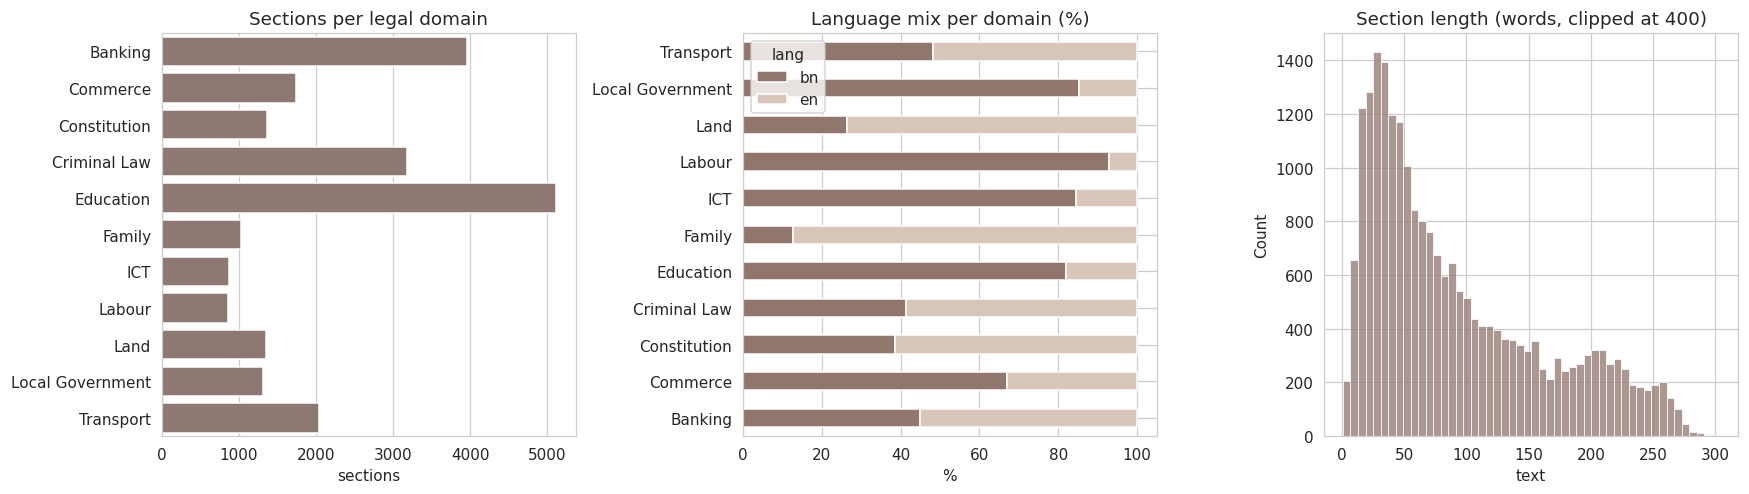

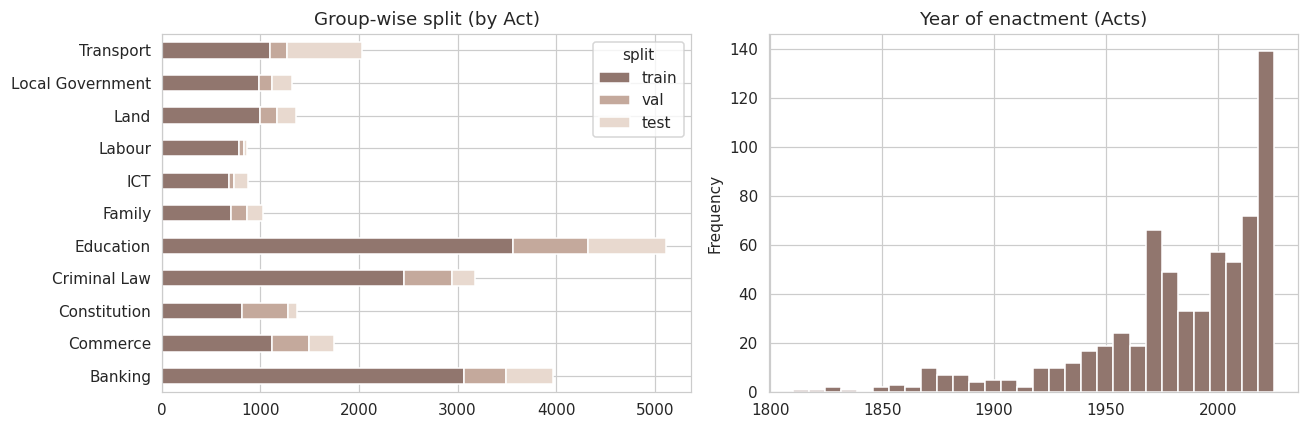

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
cnt = df.groupby('label').size().reindex(CLASSES)
sns.barplot(y=[SHORT[c] for c in CLASSES], x=cnt.values, ax=ax[0], color='#91766E'); ax[0].set_title('Sections per legal domain'); ax[0].set_xlabel('sections')
lang = pd.crosstab(df.label, df.lang, normalize='index').reindex(CLASSES) * 100
lang.index = [SHORT[c] for c in lang.index]; lang.plot(kind='barh', stacked=True, ax=ax[1], color=['#91766E', '#D9C6BB']); ax[1].set_title('Language mix per domain (%)'); ax[1].set_xlabel('%')
sns.histplot(df.text.str.split().str.len().clip(upper=400), bins=50, ax=ax[2], color='#91766E'); ax[2].set_title('Section length (words, clipped at 400)')
savefig('eda_data_overview')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sp = pd.crosstab(df.label, df.split).reindex(CLASSES)[['train', 'val', 'test']]; sp.index = [SHORT[c] for c in sp.index]
sp.plot(kind='barh', stacked=True, ax=ax[0], color=['#91766E', '#C4A99C', '#E8D9CF']); ax[0].set_title('Group-wise split (by Act)')
df.drop_duplicates('act_id').year.dropna().astype(int).plot(kind='hist', bins=30, ax=ax[1], color='#91766E'); ax[1].set_title('Year of enactment (Acts)')
savefig('eda_split_years')

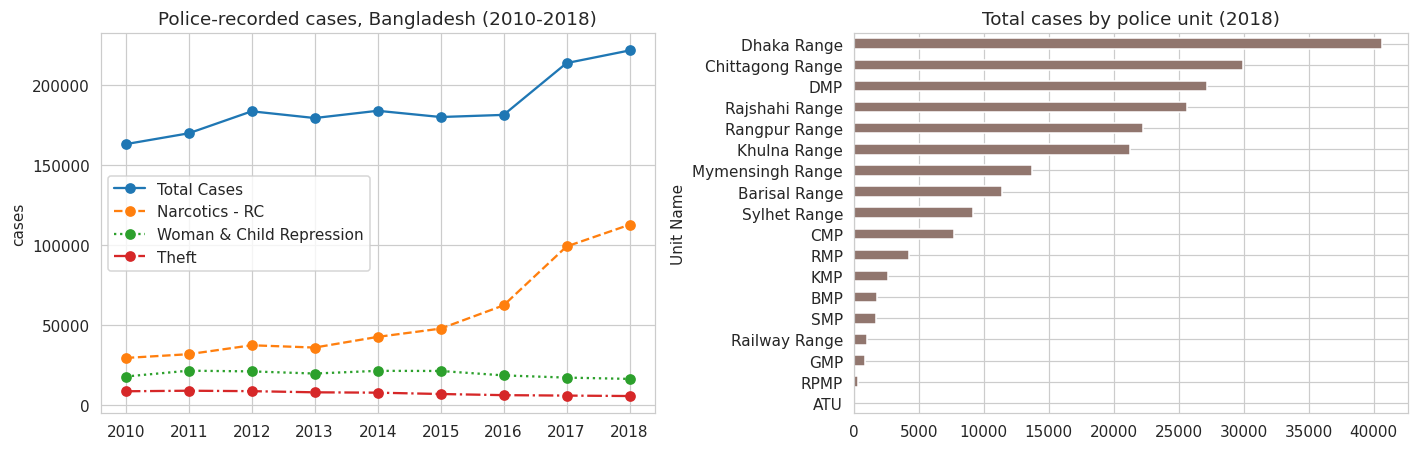

In [8]:
# Crime statistics (police-recorded cases, Bangladesh): trends 2010-2018; 2019 holds only a fraction of a year and is excluded
try:
    CRIME = find_file(['BD_Crime_Statistics_2010-2019.xls', '/content/BD_Crime_Statistics_2010-2019.xls',
                       '/content/drive/MyDrive/legal-ai/BD_Crime_Statistics_2010-2019.xls'], 'BD_Crime_Statistics_2010-2019.xls')
    crime = pd.read_csv(CRIME, encoding='utf-8-sig')      # the .xls is a CSV file
    tot = crime[crime['Unit Name'] == 'Total'].set_index('Year')
    ys = [y for y in tot.index if tot.loc[y, 'Total Cases'] > 0.5 * tot['Total Cases'].median()]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for col, st in [('Total Cases', '-'), ('Narcotics - RC', '--'), ('Woman & Child Repression', ':'), ('Theft', '-.')]:
        ax[0].plot(ys, tot.loc[ys, col], st, marker='o', label=col)
    ax[0].set_title('Police-recorded cases, Bangladesh (2010-2018)'); ax[0].legend(); ax[0].set_ylabel('cases')
    units = crime[(crime.Year == ys[-1]) & (crime['Unit Name'] != 'Total')].set_index('Unit Name')['Total Cases'].sort_values()
    units.plot(kind='barh', ax=ax[1], color='#91766E'); ax[1].set_title(f'Total cases by police unit ({ys[-1]})')
    savefig('eda_crime_statistics')
except Exception as e:
    print('Crime-statistics plot skipped:', e)

## 6 · Vectorisation
Four representations are built from the training split only (no leakage):
1. **TF-IDF word 1-2-grams** on stemmed tokens · 2. **TF-IDF character 2-5-grams** (robust to Bengali inflection and OCR noise) · 3. **TruncatedSVD (LSA)** of both, for tree models · 4. **Word2Vec (skip-gram)** vectors that initialise the Keras networks. Transformers use their own **subword tokenisers** (section 9).

word TF-IDF 65,830 · char TF-IDF 86,656 · combined (16259, 152486) · SVD 200 dims (explained variance 31.34%) · 85s


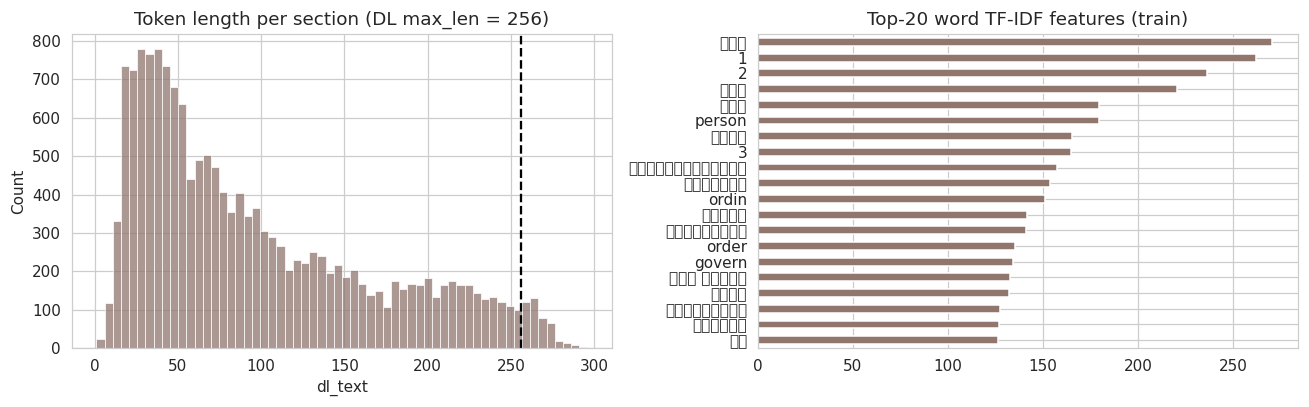

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from scipy.sparse import hstack

t0 = time.time()
for d in (tr, va, te):
    d['clean'] = d.input.map(lambda s: ' '.join(tokenise(s)))                    # stemmed word tokens
    d['norm']  = d.input.map(normalise)                                           # normalised raw text (for char n-grams / DL)
    d['dl_text'] = d.input.map(lambda s: ' '.join(tokenise(s, stop=False, do_stem=False)))

vec_w = TfidfVectorizer(ngram_range=(1, 2), min_df=2 if FAST_DEBUG else 3, max_features=20000 if FAST_DEBUG else 80000, sublinear_tf=True, token_pattern=r'\S+')
vec_c = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2 if FAST_DEBUG else 5, max_features=20000 if FAST_DEBUG else 120000, sublinear_tf=True)
Xw = {k: (vec_w.fit_transform(d.clean) if k == 'tr' else vec_w.transform(d.clean)) for k, d in zip(['tr', 'va', 'te'], [tr, va, te])}
Xc = {k: (vec_c.fit_transform(d.norm)  if k == 'tr' else vec_c.transform(d.norm))  for k, d in zip(['tr', 'va', 'te'], [tr, va, te])}
X = {k: hstack([Xw[k], Xc[k]]).tocsr() for k in Xw}
svd = TruncatedSVD(n_components=40 if FAST_DEBUG else 200, random_state=SEED)
Z = {'tr': svd.fit_transform(X['tr'])}; Z['va'] = svd.transform(X['va']); Z['te'] = svd.transform(X['te'])
print(f'word TF-IDF {Xw["tr"].shape[1]:,} · char TF-IDF {Xc["tr"].shape[1]:,} · combined {X["tr"].shape} · SVD {Z["tr"].shape[1]} dims '
      f'(explained variance {svd.explained_variance_ratio_.sum():.2%}) · {time.time()-t0:.0f}s')

lens = tr.dl_text.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(lens.clip(upper=600), bins=60, ax=ax[0], color='#91766E'); ax[0].axvline(256, color='k', ls='--'); ax[0].set_title('Token length per section (DL max_len = 256)')
top = pd.Series(np.asarray(Xw['tr'].sum(0)).ravel(), index=vec_w.get_feature_names_out()).nlargest(20)
top.sort_values().plot(kind='barh', ax=ax[1], color='#91766E'); ax[1].set_title('Top-20 word TF-IDF features (train)')
savefig('vectorisation_overview')

## 7 · Evaluation utilities

In [10]:
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
                             classification_report, log_loss, top_k_accuracy_score)
RESULTS = {}      # name -> metrics + validation/test probability matrices (used by the ensembles)
FAMILY_COLOR = {'ML': '#4C78A8', 'DL': '#F58518', 'Ensemble': '#54A24B', 'LLM': '#B279A2'}

def metrics_of(y, P):
    pred = P.argmax(1)
    return dict(acc=accuracy_score(y, pred), f1_macro=f1_score(y, pred, average='macro'), f1_weighted=f1_score(y, pred, average='weighted'),
                bal_acc=balanced_accuracy_score(y, pred), mcc=matthews_corrcoef(y, pred),
                top2=top_k_accuracy_score(y, P, k=2, labels=range(C)), logloss=log_loss(y, np.clip(P, 1e-9, 1), labels=range(C)))

def register(name, family, P_va, P_te, seconds, epochs=None, params=''):
    m = metrics_of(yte, P_te)
    RESULTS[name] = dict(family=family, P_val=P_va, P_test=P_te, seconds=seconds, epochs=epochs, params=params,
                         val_f1=f1_score(yva, P_va.argmax(1), average='macro'), **m)
    print(f'{name:<34} acc={m["acc"]:.3f}  macro-F1={m["f1_macro"]:.3f}  MCC={m["mcc"]:.3f}  top-2={m["top2"]:.3f}  ({seconds:.0f}s)')

def plot_cm(P, title, ax=None, y=None, normalise_rows=True):
    y = yte if y is None else y
    cm = confusion_matrix(y, P.argmax(1), labels=range(C)).astype(float)
    shown = cm / cm.sum(1, keepdims=True).clip(min=1) if normalise_rows else cm
    ax = ax or plt.gca()
    sns.heatmap(shown, annot=cm.astype(int) if C <= 12 else False, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=[SHORT[c] for c in CLASSES], yticklabels=[SHORT[c] for c in CLASSES], vmin=0, vmax=1, annot_kws={'size': 7})
    ax.set_title(title, fontsize=10); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right', fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)

def plot_history(hist, name):
    h = hist.history; fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); ep = range(1, len(h['loss']) + 1)
    ax[0].plot(ep, h['loss'], 'o-', label='train'); ax[0].plot(ep, h['val_loss'], 's-', label='validation'); ax[0].set_title(f'{name} — loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(ep, h['accuracy'], 'o-', label='train'); ax[1].plot(ep, h['val_accuracy'], 's-', label='validation'); ax[1].set_title(f'{name} — accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
    savefig(f'curves_{name.lower().replace(" ", "_")}')

## 8 · Machine-learning models (5)
All classical models use **balanced class weights**; Logistic Regression and the Linear SVM are tuned with **randomised search + Act-grouped K-fold** (macro-F1). Random Forest and XGBoost run on the LSA features; XGBoost uses early stopping on the validation split.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from scipy.stats import loguniform
from xgboost import XGBClassifier

gkf = list(GroupKFold(n_splits=3).split(X['tr'], ytr, groups=tr.act_id))
N_ITER = 2 if FAST_DEBUG else 4

# 1 ── Logistic Regression (multinomial) ──────────────────────────────
t0 = time.time()
lr_cv = RandomizedSearchCV(LogisticRegression(max_iter=300, class_weight='balanced'), {'C': loguniform(1, 60)}, n_iter=N_ITER, cv=gkf,
                           scoring='f1_macro', random_state=SEED, n_jobs=1, refit=True)
lr_cv.fit(X['tr'], ytr); lr = lr_cv.best_estimator_
register('Logistic Regression', 'ML', lr.predict_proba(X['va']), lr.predict_proba(X['te']), time.time() - t0, params=f"C={lr_cv.best_params_['C']:.2f}, CV-F1={lr_cv.best_score_:.3f}")

# 2 ── Linear SVM (probabilities via sigmoid calibration) ─────────────
t0 = time.time()
svm_cv = RandomizedSearchCV(LinearSVC(class_weight='balanced'), {'C': loguniform(0.05, 5)}, n_iter=N_ITER, cv=gkf, scoring='f1_macro',
                            random_state=SEED, n_jobs=1, refit=False).fit(X['tr'], ytr)
svm = CalibratedClassifierCV(LinearSVC(C=svm_cv.best_params_['C'], class_weight='balanced'), cv=gkf, method='sigmoid').fit(X['tr'], ytr)
register('Linear SVM', 'ML', svm.predict_proba(X['va']), svm.predict_proba(X['te']), time.time() - t0, params=f"C={svm_cv.best_params_['C']:.2f}, CV-F1={svm_cv.best_score_:.3f}")

# 3 ── Complement Naive Bayes (word TF-IDF) ───────────────────────────
t0 = time.time()
best_a, best_f = None, -1
for a in [0.03, 0.1, 0.3, 1.0]:                                     # alpha selected on the validation split
    f = f1_score(yva, ComplementNB(alpha=a).fit(Xw['tr'], ytr).predict(Xw['va']), average='macro')
    if f > best_f: best_a, best_f = a, f
nb = ComplementNB(alpha=best_a).fit(Xw['tr'], ytr)
register('Complement NB', 'ML', nb.predict_proba(Xw['va']), nb.predict_proba(Xw['te']), time.time() - t0, params=f'alpha={best_a}')

# 4 ── Random Forest (LSA features) ───────────────────────────────────
t0 = time.time()
rf = RandomForestClassifier(n_estimators=60 if FAST_DEBUG else 400, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED).fit(Z['tr'], ytr)
register('Random Forest', 'ML', rf.predict_proba(Z['va']), rf.predict_proba(Z['te']), time.time() - t0, params=f'{rf.n_estimators} trees')

# 5 ── XGBoost (LSA features, early stopping) ─────────────────────────
t0 = time.time()
xgb = XGBClassifier(n_estimators=60 if FAST_DEBUG else 600, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, objective='multi:softprob',
                    tree_method='hist', device='cuda' if GPU else 'cpu', eval_metric='mlogloss', early_stopping_rounds=30, random_state=SEED, n_jobs=-1)
xgb.fit(Z['tr'], ytr, sample_weight=compute_sample_weight('balanced', ytr), eval_set=[(Z['va'], yva)], verbose=False)
register('XGBoost', 'ML', xgb.predict_proba(Z['va']), xgb.predict_proba(Z['te']), time.time() - t0, epochs=xgb.best_iteration + 1, params=f'{xgb.best_iteration + 1} boosting rounds')

Logistic Regression                acc=0.625  macro-F1=0.496  MCC=0.565  top-2=0.730  (714s)
Linear SVM                         acc=0.624  macro-F1=0.480  MCC=0.562  top-2=0.736  (193s)
Complement NB                      acc=0.573  macro-F1=0.441  MCC=0.505  top-2=0.699  (0s)
Random Forest                      acc=0.526  macro-F1=0.388  MCC=0.452  top-2=0.649  (52s)
XGBoost                            acc=0.545  macro-F1=0.423  MCC=0.476  top-2=0.665  (9s)


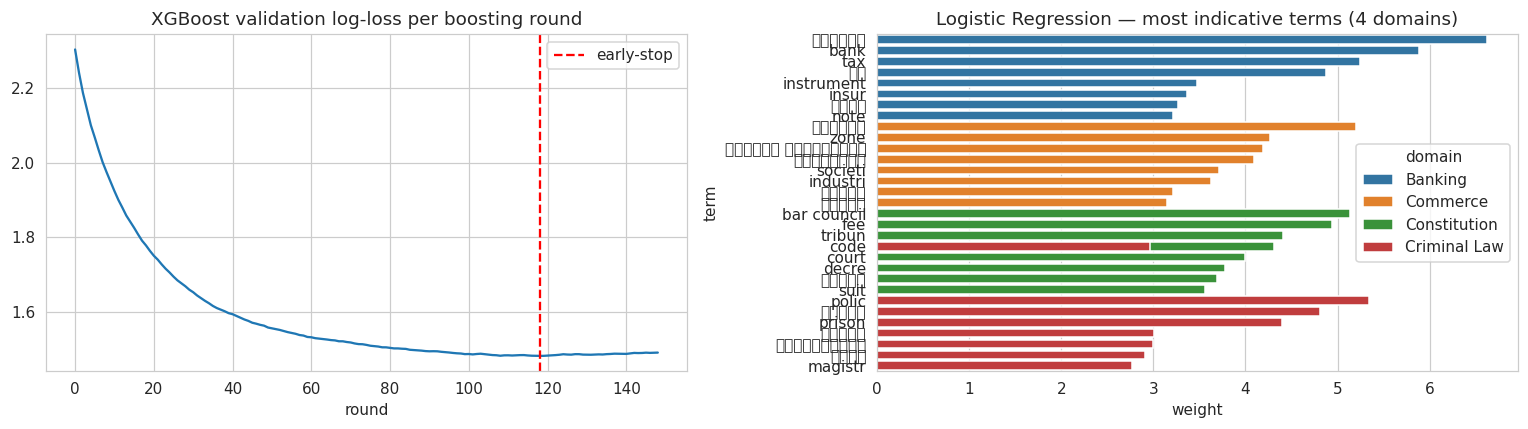

In [12]:
# XGBoost training curve and LR interpretability (top terms per domain)
ev = xgb.evals_result()['validation_0']['mlogloss']
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ev); ax[0].axvline(xgb.best_iteration, color='r', ls='--', label='early-stop'); ax[0].set_title('XGBoost validation log-loss per boosting round'); ax[0].legend(); ax[0].set_xlabel('round')
nw = len(vec_w.vocabulary_); names = vec_w.get_feature_names_out()
pick = CLASSES[:4]
rows = []
for c in pick:
    w = lr.coef_[cls2id[c], :nw]; idx = np.argsort(-w)[:8]
    rows += [(SHORT[c], names[i], w[i]) for i in idx]
tt = pd.DataFrame(rows, columns=['domain', 'term', 'weight'])
sns.barplot(data=tt, y='term', x='weight', hue='domain', dodge=False, ax=ax[1]); ax[1].set_title('Logistic Regression — most indicative terms (4 domains)')
savefig('ml_xgb_curve_and_lr_terms')

## 9 · Deep-learning models, part 1 — Keras (TextCNN & BiLSTM-Attention)
**Tokenisation:** whitespace word tokens over normalised text → integer ids (vocabulary of the 40 000 most frequent train tokens, `<pad>`=0, `<unk>`=1), sequences padded/truncated to 256 tokens.  **Vectorisation:** skip-gram **Word2Vec** (128-d) trained on the training split initialises the embedding layer (fine-tuned).  **Training:** Adam, class-weighted cross-entropy, up to **30 epochs** with early stopping (patience 4) and learning-rate decay.

I0000 00:00:1794923181.996061     117 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


vocabulary 20,914 · Word2Vec coverage 100.0% · 64s
Epoch 1/30
128/128 - 21s - 161ms/step - accuracy: 0.2456 - loss: 2.1948 - val_accuracy: 0.2969 - val_loss: 2.0801 - learning_rate: 0.0010
Epoch 2/30
128/128 - 4s - 31ms/step - accuracy: 0.4567 - loss: 1.7245 - val_accuracy: 0.4604 - val_loss: 1.6963 - learning_rate: 0.0010
Epoch 3/30
128/128 - 4s - 31ms/step - accuracy: 0.6150 - loss: 1.2575 - val_accuracy: 0.5224 - val_loss: 1.4694 - learning_rate: 0.0010
Epoch 4/30
128/128 - 4s - 31ms/step - accuracy: 0.6901 - loss: 1.0036 - val_accuracy: 0.5436 - val_loss: 1.4251 - learning_rate: 0.0010
Epoch 5/30
128/128 - 4s - 31ms/step - accuracy: 0.7377 - loss: 0.8237 - val_accuracy: 0.5647 - val_loss: 1.4300 - learning_rate: 0.0010
Epoch 6/30
128/128 - 4s - 32ms/step - accuracy: 0.7740 - loss: 0.7076 - val_accuracy: 0.5669 - val_loss: 1.4344 - learning_rate: 0.0010
Epoch 7/30
128/128 - 4s - 32ms/step - accuracy: 0.8027 - loss: 0.6027 - val_accuracy: 0.5856 - val_loss: 1.4433 - learning_rate: 5.

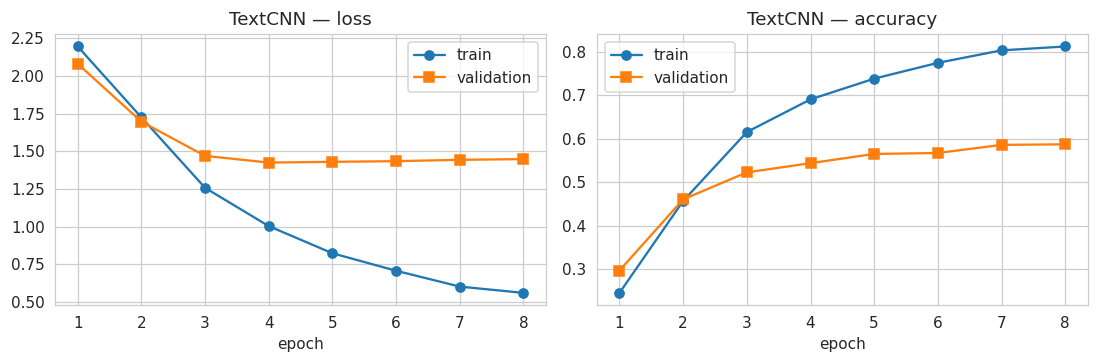

TextCNN                            acc=0.562  macro-F1=0.447  MCC=0.500  top-2=0.660  (62s)
Epoch 1/30
128/128 - 12s - 90ms/step - accuracy: 0.3643 - loss: 1.9524 - val_accuracy: 0.4353 - val_loss: 1.7513 - learning_rate: 0.0010
Epoch 2/30
128/128 - 5s - 40ms/step - accuracy: 0.6313 - loss: 1.2531 - val_accuracy: 0.5347 - val_loss: 1.5050 - learning_rate: 0.0010
Epoch 3/30
128/128 - 5s - 40ms/step - accuracy: 0.7242 - loss: 0.9429 - val_accuracy: 0.5807 - val_loss: 1.4398 - learning_rate: 0.0010
Epoch 4/30
128/128 - 5s - 41ms/step - accuracy: 0.7704 - loss: 0.7703 - val_accuracy: 0.5813 - val_loss: 1.4729 - learning_rate: 0.0010
Epoch 5/30
128/128 - 5s - 41ms/step - accuracy: 0.7945 - loss: 0.6755 - val_accuracy: 0.5920 - val_loss: 1.4809 - learning_rate: 0.0010
Epoch 6/30
128/128 - 5s - 41ms/step - accuracy: 0.8219 - loss: 0.5694 - val_accuracy: 0.6049 - val_loss: 1.4896 - learning_rate: 5.0000e-04
Epoch 7/30
128/128 - 5s - 42ms/step - accuracy: 0.8313 - loss: 0.5280 - val_accuracy: 0

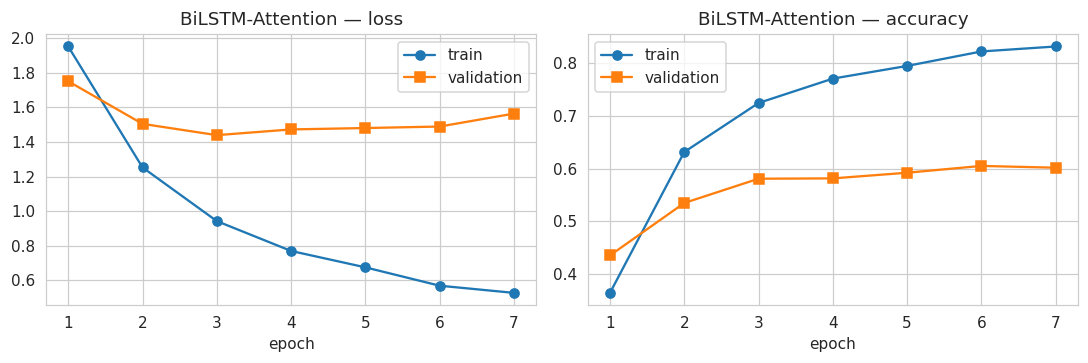

BiLSTM-Attention                   acc=0.561  macro-F1=0.442  MCC=0.496  top-2=0.662  (46s)


In [13]:
os.environ.setdefault('KERAS_BACKEND', 'tensorflow')
import keras
from keras import layers, ops
from gensim.models import Word2Vec
keras.utils.set_random_seed(SEED)

MAXLEN, EMB, EPOCHS = (64, 32, 2) if FAST_DEBUG else (256, 128, 30)
def build_vocab(texts, max_tokens=40000, min_freq=2):
    cnt = collections.Counter(w for t in texts for w in t.split())
    itos = ['<pad>', '<unk>'] + [w for w, c in cnt.most_common(max_tokens - 2) if c >= min_freq]
    return {w: i for i, w in enumerate(itos)}
def encode(texts, vocab, maxlen=MAXLEN):
    arr = np.zeros((len(texts), maxlen), dtype='int32')
    for i, t in enumerate(texts):
        ids = [vocab.get(w, 1) for w in t.split()][:maxlen]; arr[i, :len(ids)] = ids
    return arr

vocab = build_vocab(tr.dl_text); V = len(vocab)
Itr, Iva, Ite = (encode(d.dl_text, vocab) for d in (tr, va, te))
t0 = time.time()
w2v = Word2Vec([t.split() for t in tr.dl_text], vector_size=EMB, window=5, min_count=2, sg=1, workers=2, epochs=3 if FAST_DEBUG else 12, seed=SEED)
emb = np.random.normal(0, 0.05, (V, EMB)).astype('float32'); hit = 0
for w, i in vocab.items():
    if w in w2v.wv: emb[i] = w2v.wv[w]; hit += 1
emb[0] = 0
print(f'vocabulary {V:,} · Word2Vec coverage {hit / V:.1%} · {time.time() - t0:.0f}s')

class AttentionPool(layers.Layer):
    # additive attention over time steps -> weighted sum
    def __init__(self, units=64, **kw):
        super().__init__(**kw); self.proj = layers.Dense(units, activation='tanh'); self.score = layers.Dense(1, use_bias=False)
    def call(self, x):
        a = ops.softmax(self.score(self.proj(x)), axis=1)
        return ops.sum(a * x, axis=1)

def build_textcnn():
    inp = keras.Input((MAXLEN,), dtype='int32')
    x = layers.Embedding(V, EMB, embeddings_initializer=keras.initializers.Constant(emb))(inp)
    x = layers.SpatialDropout1D(0.2)(x)
    pools = [layers.GlobalMaxPooling1D()(layers.Conv1D(96 if FAST_DEBUG else 128, k, activation='relu', padding='same')(x)) for k in (2, 3, 4, 5)]
    x = layers.Dropout(0.4)(layers.Concatenate()(pools))
    x = layers.Dense(128, activation='relu')(x)
    return keras.Model(inp, layers.Dense(C, activation='softmax')(layers.Dropout(0.3)(x)), name='TextCNN')

def build_bilstm():
    inp = keras.Input((MAXLEN,), dtype='int32')
    x = layers.Embedding(V, EMB, embeddings_initializer=keras.initializers.Constant(emb))(inp)
    x = layers.SpatialDropout1D(0.2)(x)
    x = layers.Bidirectional(layers.LSTM(32 if FAST_DEBUG else 96, return_sequences=True))(x)
    x = layers.Dropout(0.4)(AttentionPool()(x))
    x = layers.Dense(128, activation='relu')(x)
    return keras.Model(inp, layers.Dense(C, activation='softmax')(layers.Dropout(0.3)(x)), name='BiLSTM_Attention')

cw = dict(enumerate(compute_class_weight('balanced', classes=np.arange(C), y=ytr)))
HISTORY = {}
def train_keras(builder, label):
    t0 = time.time(); m = builder()
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)]
    h = m.fit(Itr, ytr, validation_data=(Iva, yva), epochs=EPOCHS, batch_size=128, class_weight=cw, callbacks=cb, verbose=2)
    HISTORY[label] = h; plot_history(h, label)
    register(label, 'DL', m.predict(Iva, verbose=0), m.predict(Ite, verbose=0), time.time() - t0, epochs=len(h.history['loss']), params=f'{m.count_params():,} params')
    return m

cnn = train_keras(build_textcnn, 'TextCNN')
bilstm = train_keras(build_bilstm, 'BiLSTM-Attention')

## 10 · Deep-learning models, part 2 — transformers
**Subword tokenisation.** XLM-RoBERTa uses a 250k-token SentencePiece vocabulary shared by Bengali and English, so inflected Bengali words split into stable pieces instead of becoming `<unk>`.

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (549 > 512). Running this sequence through the model will result in indexing errors


20 tokens -> ['▁Who', 'ever', '▁com', 'mit', 's', '▁the', 'ft', '▁shall', '▁be', '▁pun', 'is', 'hed', '▁with', '▁im', 'pris', 'on', 'ment', '.']
18 tokens -> ['▁যে', '▁ব্যক্তি', '▁চু', 'রি', '▁করে', '▁তা', 'হা', 'কে', '▁কারা', 'দ', 'ণ্ড', '▁দেওয়া', '▁হ', 'ই', 'বে', '।']


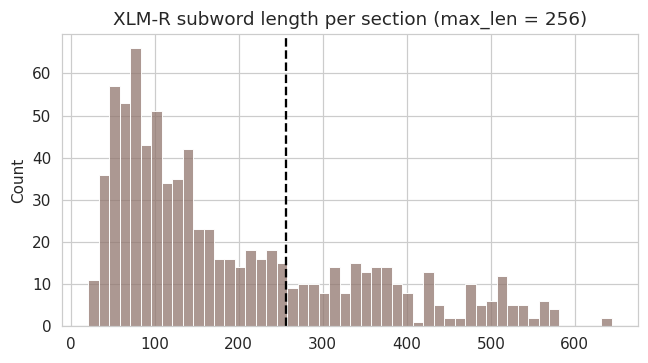

In [14]:
if USE_HF:
    from transformers import AutoTokenizer
    xtok = AutoTokenizer.from_pretrained('xlm-roberta-base')
    for s in ['Whoever commits theft shall be punished with imprisonment.', 'যে ব্যক্তি চুরি করে তাহাকে কারাদণ্ড দেওয়া হইবে।']:
        print(len(xtok(s)['input_ids']), 'tokens ->', xtok.tokenize(s)[:24])
    L = [len(xtok(t, truncation=False)['input_ids']) for t in tr.input.sample(min(800, len(tr)), random_state=SEED)]
    plt.figure(figsize=(6, 3.4)); sns.histplot(np.clip(L, 0, 800), bins=50, color='#91766E'); plt.axvline(256, color='k', ls='--'); plt.title('XLM-R subword length per section (max_len = 256)')
    savefig('xlmr_token_lengths')
else:
    print('USE_HF=0 -> transformer cells skipped')

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1 Macro,Acc
1,0.939282,1.383993,0.507806,0.585276
2,0.693307,1.404695,0.511011,0.601534
3,0.545784,1.422543,0.536479,0.618098


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

XLM-RoBERTa (fine-tuned)           acc=0.668  macro-F1=0.558  MCC=0.619  top-2=0.764  (1314s)


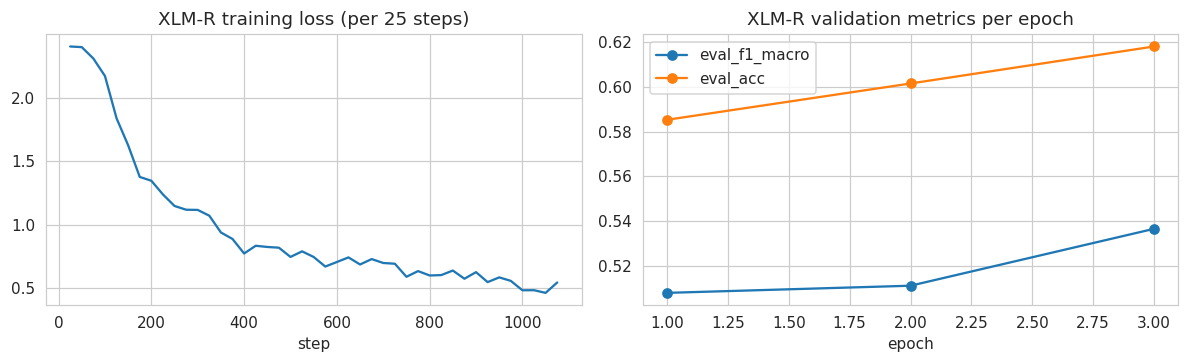

In [15]:
# XLM-RoBERTa-base fine-tuning: 3 epochs, AdamW 2e-5, warm-up 10 %, class-weighted loss, best epoch kept (macro-F1)
if USE_HF:
    import torch, inspect
    from torch.utils.data import Dataset
    from transformers import (AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, EarlyStoppingCallback)
    MAXTOK = 256; XLMR = 'xlm-roberta-base'
    capped = pd.concat([g.sample(min(len(g), 1500), random_state=SEED) for _, g in tr.groupby('y')])   # cap/class: keeps the run ~25 min on a T4
    class DS(Dataset):
        def __init__(self, texts, labels): self.enc = xtok(list(texts), truncation=True, max_length=MAXTOK); self.y = list(labels)
        def __len__(self): return len(self.y)
        def __getitem__(self, i): return {**{k: v[i] for k, v in self.enc.items()}, 'labels': int(self.y[i])}
    ds_tr, ds_va, ds_te = DS(capped.input, capped.y), DS(va.input, yva), DS(te.input, yte)
    cw_t = torch.tensor(compute_class_weight('balanced', classes=np.arange(C), y=capped.y.values), dtype=torch.float)

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kw):
            labels = inputs.pop('labels'); out = model(**inputs)
            loss = torch.nn.functional.cross_entropy(out.logits, labels, weight=cw_t.to(out.logits.device))
            return (loss, out) if return_outputs else loss
    def hf_metrics(p): return {'f1_macro': f1_score(p.label_ids, p.predictions.argmax(-1), average='macro'), 'acc': accuracy_score(p.label_ids, p.predictions.argmax(-1))}
    ek = 'eval_strategy' if 'eval_strategy' in inspect.signature(TrainingArguments.__init__).parameters else 'evaluation_strategy'
    
    import math
    n_gpu = max(1, torch.cuda.device_count())
    WARM = int(0.1 * math.ceil(len(ds_tr) / (16 * n_gpu)) * 3)   # 10 % of total training steps (3 epochs)
    args = TrainingArguments(output_dir='xlmr_out', num_train_epochs=3, per_device_train_batch_size=16, per_device_eval_batch_size=64, learning_rate=2e-5,
                             weight_decay=0.01, warmup_steps=WARM, save_strategy='epoch', load_best_model_at_end=True, metric_for_best_model='f1_macro',
                             fp16=GPU, logging_steps=25, report_to='none', seed=SEED, save_total_limit=1, **{ek: 'epoch'})
    t0 = time.time()
    xmodel = AutoModelForSequenceClassification.from_pretrained(XLMR, num_labels=C)
    tk = {'processing_class': xtok} if 'processing_class' in inspect.signature(Trainer.__init__).parameters else {'tokenizer': xtok}   # API changed in transformers>=4.46
    trainer = WeightedTrainer(model=xmodel, args=args, train_dataset=ds_tr, eval_dataset=ds_va, data_collator=DataCollatorWithPadding(xtok), **tk,
                              compute_metrics=hf_metrics, callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    trainer.train()
    sm = lambda a: torch.softmax(torch.tensor(a), -1).numpy()
    P_va, P_te = sm(trainer.predict(ds_va).predictions), sm(trainer.predict(ds_te).predictions)
    register('XLM-RoBERTa (fine-tuned)', 'DL', P_va, P_te, time.time() - t0, epochs=3, params=f'{sum(p.numel() for p in xmodel.parameters()) / 1e6:.0f}M params')
    lh = pd.DataFrame(trainer.state.log_history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    lh.dropna(subset=['loss']).plot(x='step', y='loss', ax=ax[0], legend=False); ax[0].set_title('XLM-R training loss (per 25 steps)')
    lh.dropna(subset=['eval_f1_macro']).plot(x='epoch', y=['eval_f1_macro', 'eval_acc'], marker='o', ax=ax[1]); ax[1].set_title('XLM-R validation metrics per epoch')
    savefig('curves_xlmr')
    del xmodel, trainer; torch.cuda.empty_cache()

In [16]:
# multilingual-E5-small: frozen sentence encoder (384-d) + class-weighted Logistic Regression head
if USE_HF:
    from sentence_transformers import SentenceTransformer
    e5 = SentenceTransformer('intfloat/multilingual-e5-small', device='cuda' if GPU else 'cpu'); e5.max_seq_length = 256
    def e5_encode(texts, prefix='passage: ', bs=128):
        return e5.encode([prefix + t for t in texts], batch_size=bs, normalize_embeddings=True, show_progress_bar=True, convert_to_numpy=True).astype('float32')
    t0 = time.time()
    Etr, Eva, Ete = (e5_encode(d.input.tolist()) for d in (tr, va, te))
    head = LogisticRegression(C=20, max_iter=1000, class_weight='balanced').fit(Etr, ytr)
    register('E5-small + LR head', 'DL', head.predict_proba(Eva), head.predict_proba(Ete), time.time() - t0, params='384-d frozen encoder')

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

Batches:   0%|          | 0/128 [00:00<?, ?it/s]

Batches:   0%|          | 0/26 [00:00<?, ?it/s]

Batches:   0%|          | 0/26 [00:00<?, ?it/s]

E5-small + LR head                 acc=0.639  macro-F1=0.521  MCC=0.586  top-2=0.747  (116s)


## 11 · Large language models (2) — zero-shot classification
**Qwen2.5-1.5B-Instruct** and **Gemini 2.5 Flash** receive the section and the 11 options and answer with one letter (no training). For Qwen the answer is read from the **next-token distribution over the option letters** (one forward pass, calibrated probabilities); Gemini returns a JSON enum. Both are scored on the same stratified test subset because LLM inference is slow.

In [17]:
N_ZS = 0 if FAST_DEBUG else 400
rng = np.random.RandomState(SEED)
ZS_IDX = np.sort(np.concatenate([rng.choice(np.where(yte == c)[0], min(int((yte == c).sum()), max(5, N_ZS // C)), replace=False) for c in range(C) if (yte == c).any()])) if N_ZS else np.array([], dtype=int)
SUBSET = {}      # name -> probability matrix on the zero-shot subset
LETTERS = [chr(65 + i) for i in range(C)]
OPTIONS = '\n'.join(f'{LETTERS[i]}) {CLASSES[i]}' for i in range(C))
def zs_text(text): return (f'Classify the legal domain of this section of a Bangladeshi statute.\n\nSection:\n---\n{text[:600]}\n---\n\nOptions:\n{OPTIONS}\n\nAnswer with a single letter.')

if USE_HF and len(ZS_IDX):
    from transformers import AutoModelForCausalLM
    LLM_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
    qtok = AutoTokenizer.from_pretrained(LLM_ID); qtok.padding_side = 'left'
    qllm = AutoModelForCausalLM.from_pretrained(LLM_ID, torch_dtype=torch.float16 if GPU else torch.float32, device_map='auto' if GPU else None).eval()
    letter_ids = [qtok.encode(l, add_special_tokens=False)[0] for l in LETTERS]
    def chat(prompt, system='You are an expert in Bangladeshi law.'):
        return qtok.apply_chat_template([{'role': 'system', 'content': system}, {'role': 'user', 'content': prompt}], tokenize=False, add_generation_prompt=True)
    @torch.no_grad()
    def qwen_letter_probs(prompts, bs=8):
        out = []
        for i in range(0, len(prompts), bs):
            enc = qtok([chat(p) for p in prompts[i:i + bs]], return_tensors='pt', padding=True).to(qllm.device)
            lg = qllm(**enc).logits[:, -1, :][:, letter_ids].float()
            out.append(torch.softmax(lg, -1).cpu().numpy())
        return np.vstack(out)
    t0 = time.time()
    SUBSET['Qwen2.5-1.5B (zero-shot)'] = qwen_letter_probs([zs_text(t) for t in te.input.values[ZS_IDX]])
    p = SUBSET['Qwen2.5-1.5B (zero-shot)']
    print(f'Qwen zero-shot on {len(ZS_IDX)} test sections: acc={accuracy_score(yte[ZS_IDX], p.argmax(1)):.3f}  macro-F1={f1_score(yte[ZS_IDX], p.argmax(1), average="macro"):.3f}  ({time.time() - t0:.0f}s)')
else:
    print('LLM zero-shot skipped (USE_HF=0 or FAST_DEBUG)')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen zero-shot on 383 test sections: acc=0.420  macro-F1=0.416  (46s)


In [18]:
# Gemini 2.5 Flash (optional): set GEMINI_API_KEY in Colab Secrets (key icon) or as an environment variable
import requests
def get_key():
    k = os.environ.get('GEMINI_API_KEY')
    if k: return k
    try:
        from google.colab import userdata; return userdata.get('GEMINI_API_KEY')
    except Exception: return None
GKEY = get_key()
GEMINI_URL = 'https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent'
def gemini_call(prompt, schema=None, temperature=0.0, retries=4):
    body = {'contents': [{'role': 'user', 'parts': [{'text': prompt}]}], 'generationConfig': {'temperature': temperature}}
    if schema: body['generationConfig'].update({'responseMimeType': 'application/json', 'responseSchema': schema})
    for k in range(retries):
        r = requests.post(GEMINI_URL, params={'key': GKEY}, json=body, timeout=60)
        if r.status_code == 200: return r.json()['candidates'][0]['content']['parts'][0]['text']
        time.sleep(2 ** k)
    return None

if GKEY and len(ZS_IDX):
    schema = {'type': 'OBJECT', 'properties': {'letter': {'type': 'STRING', 'enum': LETTERS}}, 'required': ['letter']}
    G = np.full((len(ZS_IDX), C), 1e-3); t0 = time.time()
    for j, i in enumerate(ZS_IDX[:150]):                         # 150 sections keep the free-tier quota safe
        out = gemini_call(zs_text(te.input.values[i]), schema)
        try: G[j, LETTERS.index(json.loads(out)['letter'])] = 1.0
        except Exception: pass
        time.sleep(0.25)
    SUBSET['Gemini 2.5 Flash (zero-shot)'] = G[:150]
    print('Gemini 2.5 Flash on 150 sections: macro-F1 =', round(f1_score(yte[ZS_IDX[:150]], G[:150].argmax(1), average='macro'), 3), f'({time.time() - t0:.0f}s)')
else:
    print('Gemini skipped (no GEMINI_API_KEY) — the LLM count is then 1 (Qwen)')

Gemini skipped (no GEMINI_API_KEY) — the LLM count is then 1 (Qwen)


## 12 · Ensembles
The base models (5 ML + 4 DL) produce class-probability matrices on the **validation** and **test** sets. Three ensembles are built; **only the validation split is used to fit ensemble weights / the meta-learner**, so the test set stays untouched.
* **Soft voting** — mean of all probabilities.
* **Weighted soft voting** — non-negative weights (sum 1) minimising validation log-loss (SLSQP).
* **Stacking** — multinomial Logistic Regression on the concatenated log-probabilities of every base model.

base models: ['Logistic Regression', 'Linear SVM', 'Complement NB', 'Random Forest', 'XGBoost', 'TextCNN', 'BiLSTM-Attention', 'XLM-RoBERTa (fine-tuned)', 'E5-small + LR head']
Ensemble: soft voting              acc=0.663  macro-F1=0.542  MCC=0.610  top-2=0.785  (0s)
Ensemble: weighted voting          acc=0.683  macro-F1=0.577  MCC=0.635  top-2=0.797  (0s)
Ensemble: stacking (LR meta)       acc=0.624  macro-F1=0.488  MCC=0.568  top-2=0.718  (60s)


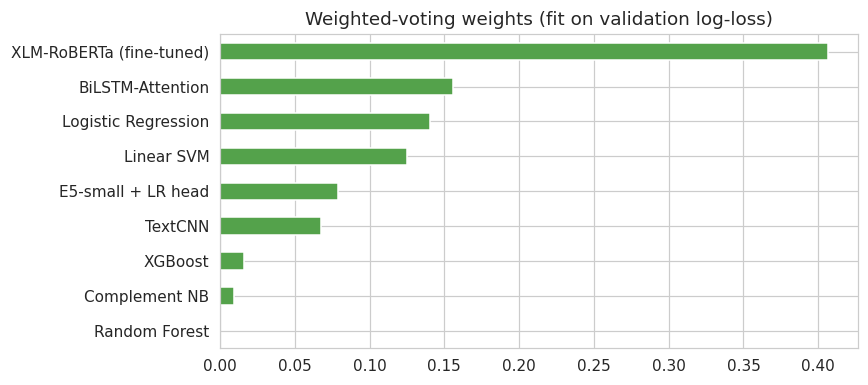

In [19]:
from scipy.optimize import minimize
BASE = [n for n, r in RESULTS.items() if r['family'] in ('ML', 'DL')]
Pv = {n: RESULTS[n]['P_val'] for n in BASE}; Pt = {n: RESULTS[n]['P_test'] for n in BASE}
print('base models:', BASE)

t0 = time.time()
register('Ensemble: soft voting', 'Ensemble', sum(Pv.values()) / len(BASE), sum(Pt.values()) / len(BASE), time.time() - t0)

def blend(w, P):
    w = np.abs(w) / np.abs(w).sum(); return sum(wi * P[n] for wi, n in zip(w, BASE))
opt = minimize(lambda w: log_loss(yva, np.clip(blend(w, Pv), 1e-9, 1), labels=range(C)), x0=np.ones(len(BASE)) / len(BASE),
               method='SLSQP', bounds=[(0, 1)] * len(BASE), constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1})
W_OPT = dict(zip(BASE, opt.x / opt.x.sum()))
register('Ensemble: weighted voting', 'Ensemble', blend(opt.x, Pv), blend(opt.x, Pt), time.time() - t0, params='weights ' + ', '.join(f'{k.split()[0]}={v:.2f}' for k, v in W_OPT.items()))

logit = lambda P: np.hstack([np.log(np.clip(P[n], 1e-6, 1)) for n in BASE])
meta = LogisticRegression(C=0.5, max_iter=3000, class_weight='balanced').fit(logit(Pv), yva)
register('Ensemble: stacking (LR meta)', 'Ensemble', meta.predict_proba(logit(Pv)), meta.predict_proba(logit(Pt)), time.time() - t0)

fig, ax = plt.subplots(figsize=(8, 3.6))
pd.Series(W_OPT).sort_values().plot(kind='barh', ax=ax, color='#54A24B'); ax.set_title('Weighted-voting weights (fit on validation log-loss)')
savefig('ensemble_weights')

## 13 · Results
### 13.1 Model comparison with Act-clustered bootstrap confidence intervals

,model,family,accuracy,macro_F1,F1_CI_low,F1_CI_high,weighted_F1,balanced_acc,MCC,top2,log_loss,val_macro_F1,epochs,train_seconds,notes
0,Ensemble: weighted voting,Ensemble,0.683,0.577,0.472,0.602,0.700,0.609,0.635,0.797,1.036,0.535,NaN,0,"weights Logistic=0.14, Linear=0.13, Complement..."
1,XLM-RoBERTa (fine-tuned),DL,0.668,0.558,0.457,0.584,0.692,0.589,0.619,0.764,1.199,0.536,3.0,1314,278M params
2,Ensemble: soft voting,Ensemble,0.663,0.542,0.431,0.571,0.671,0.572,0.610,0.785,1.117,0.502,NaN,0,
3,E5-small + LR head,DL,0.639,0.521,0.416,0.543,0.662,0.572,0.586,0.747,1.213,0.449,NaN,116,384-d frozen encoder
4,Logistic Regression,ML,0.625,0.496,0.389,0.525,0.628,0.527,0.565,0.730,1.259,0.479,NaN,714,"C=11.60, CV-F1=0.464"
5,Ensemble: stacking (LR meta),Ensemble,0.624,0.488,0.379,0.528,0.641,0.513,0.568,0.718,1.997,0.859,NaN,60,
6,Linear SVM,ML,0.624,0.480,0.379,0.521,0.611,0.503,0.562,0.736,1.270,0.472,NaN,193,"C=0.28, CV-F1=0.477"
7,TextCNN,DL,0.562,0.447,0.324,0.477,0.583,0.480,0.500,0.660,1.415,0.451,8.0,62,"2,973,963 params"
8,BiLSTM-Attention,DL,0.561,0.442,0.322,0.472,0.577,0.471,0.496,0.662,1.442,0.470,7.0,46,"2,888,331 params"
9,Complement NB,ML,0.573,0.441,0.329,0.476,0.566,0.453,0.505,0.699,1.388,0.386,NaN,0,alpha=0.03


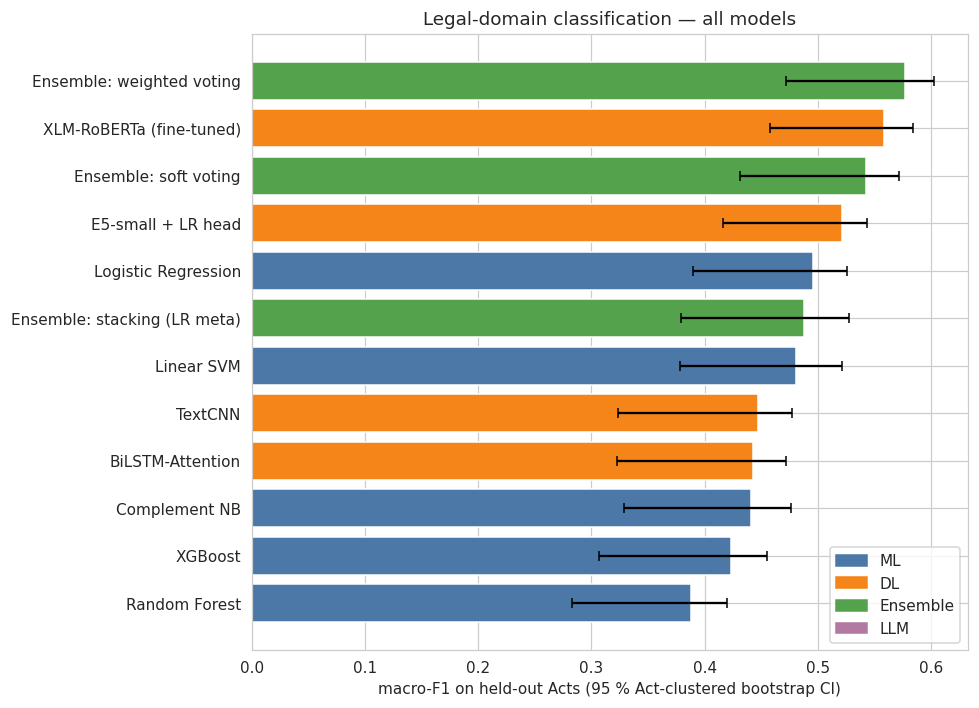

In [20]:
def cluster_boot_ci(P, y=None, groups=None, n=None):
    y = yte if y is None else y; groups = te.act_id.values if groups is None else groups; n = n or (100 if FAST_DEBUG else 600)
    rng = np.random.RandomState(0); ua = np.unique(groups); by = {a: np.where(groups == a)[0] for a in ua}; pred = P.argmax(1); s = []
    for _ in range(n):
        ii = np.concatenate([by[a] for a in rng.choice(ua, len(ua))]); s.append(f1_score(y[ii], pred[ii], average='macro'))
    return np.percentile(s, [2.5, 97.5])

rows = []
for n, r in RESULTS.items():
    lo, hi = cluster_boot_ci(r['P_test'])
    rows.append(dict(model=n, family=r['family'], accuracy=r['acc'], macro_F1=r['f1_macro'], F1_CI_low=lo, F1_CI_high=hi, weighted_F1=r['f1_weighted'],
                     balanced_acc=r['bal_acc'], MCC=r['mcc'], top2=r['top2'], log_loss=r['logloss'], val_macro_F1=r['val_f1'],
                     epochs=r['epochs'], train_seconds=round(r['seconds']), notes=r['params']))
tab = pd.DataFrame(rows).sort_values('macro_F1', ascending=False).reset_index(drop=True)
tab.to_csv(OUT / 'results_classification.csv', index=False)
display(tab.round(3))

fig, ax = plt.subplots(figsize=(9, 0.42 * len(tab) + 1.5))
tt = tab.iloc[::-1]
ax.barh(tt.model, tt.macro_F1, xerr=[(tt.macro_F1 - tt.F1_CI_low).clip(lower=0), (tt.F1_CI_high - tt.macro_F1).clip(lower=0)], color=[FAMILY_COLOR[f] for f in tt.family], capsize=3)
ax.set_xlabel('macro-F1 on held-out Acts (95 % Act-clustered bootstrap CI)'); ax.set_title('Legal-domain classification — all models')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()], labels=FAMILY_COLOR.keys(), loc='lower right')
savefig('model_comparison_macroF1')

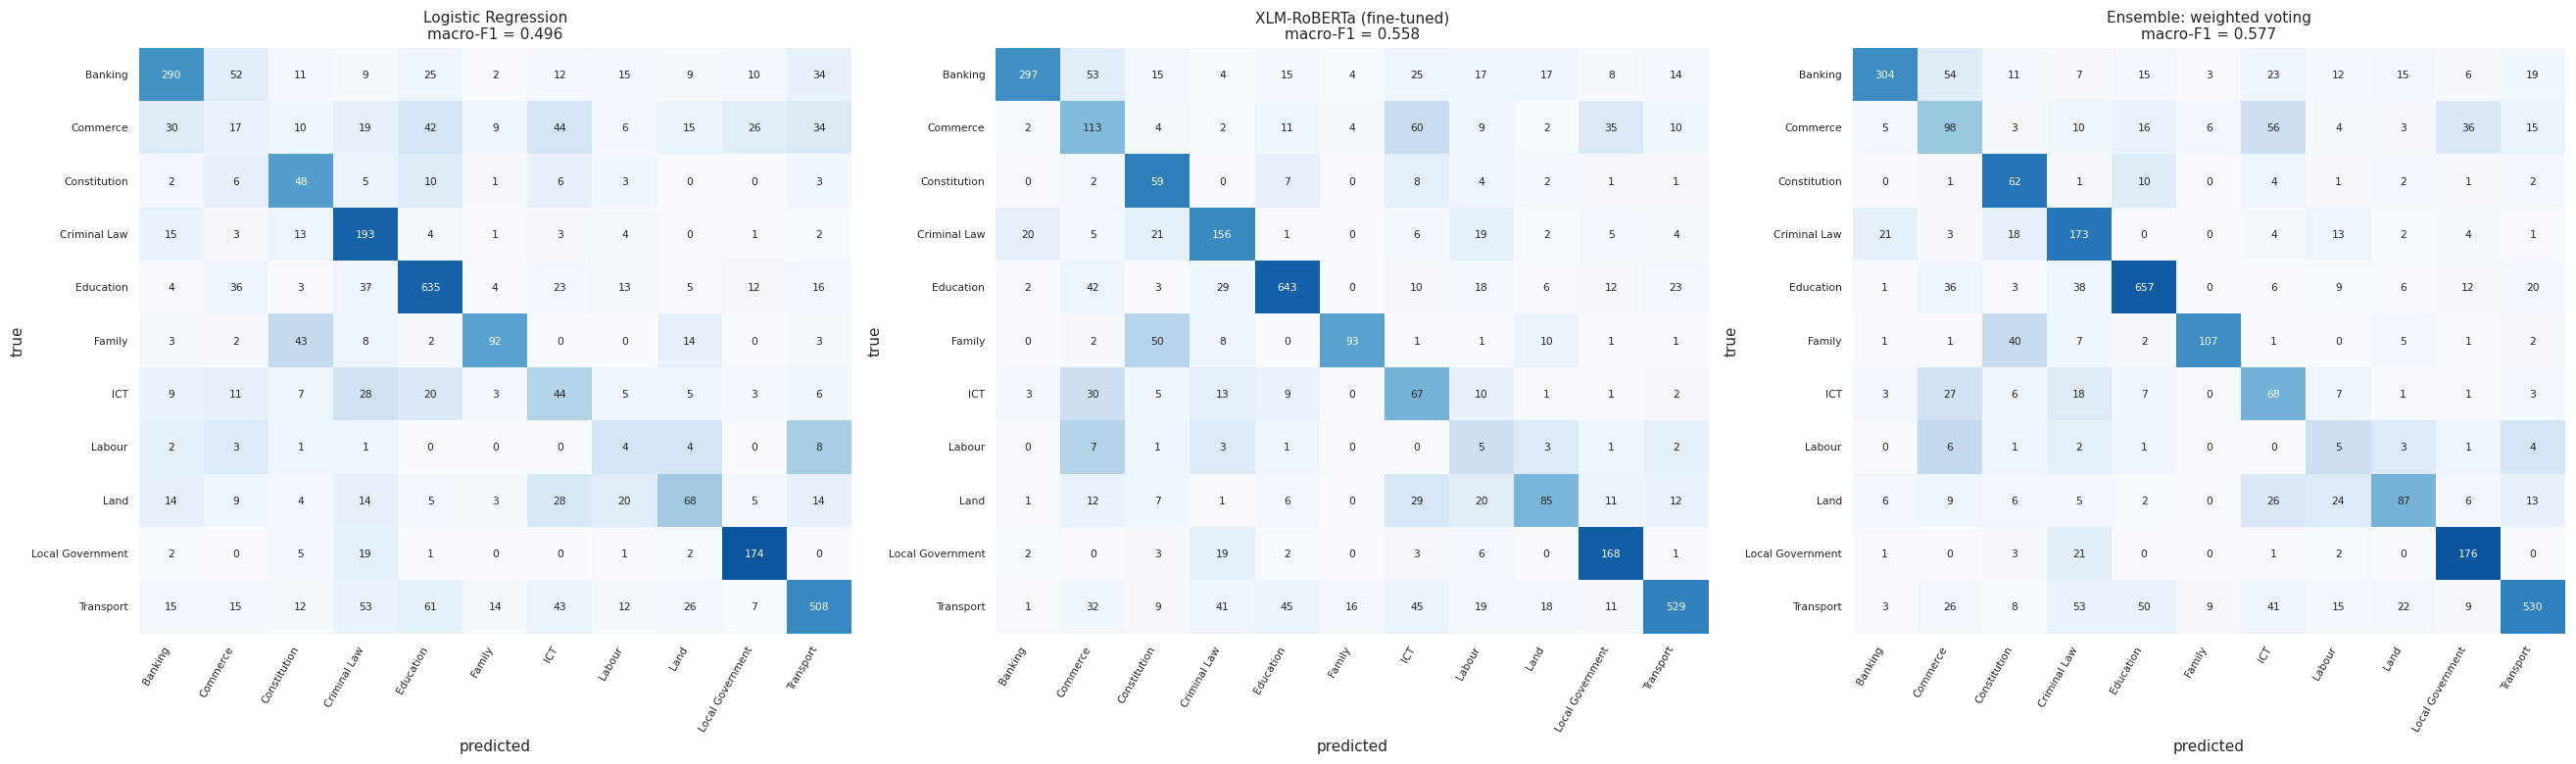

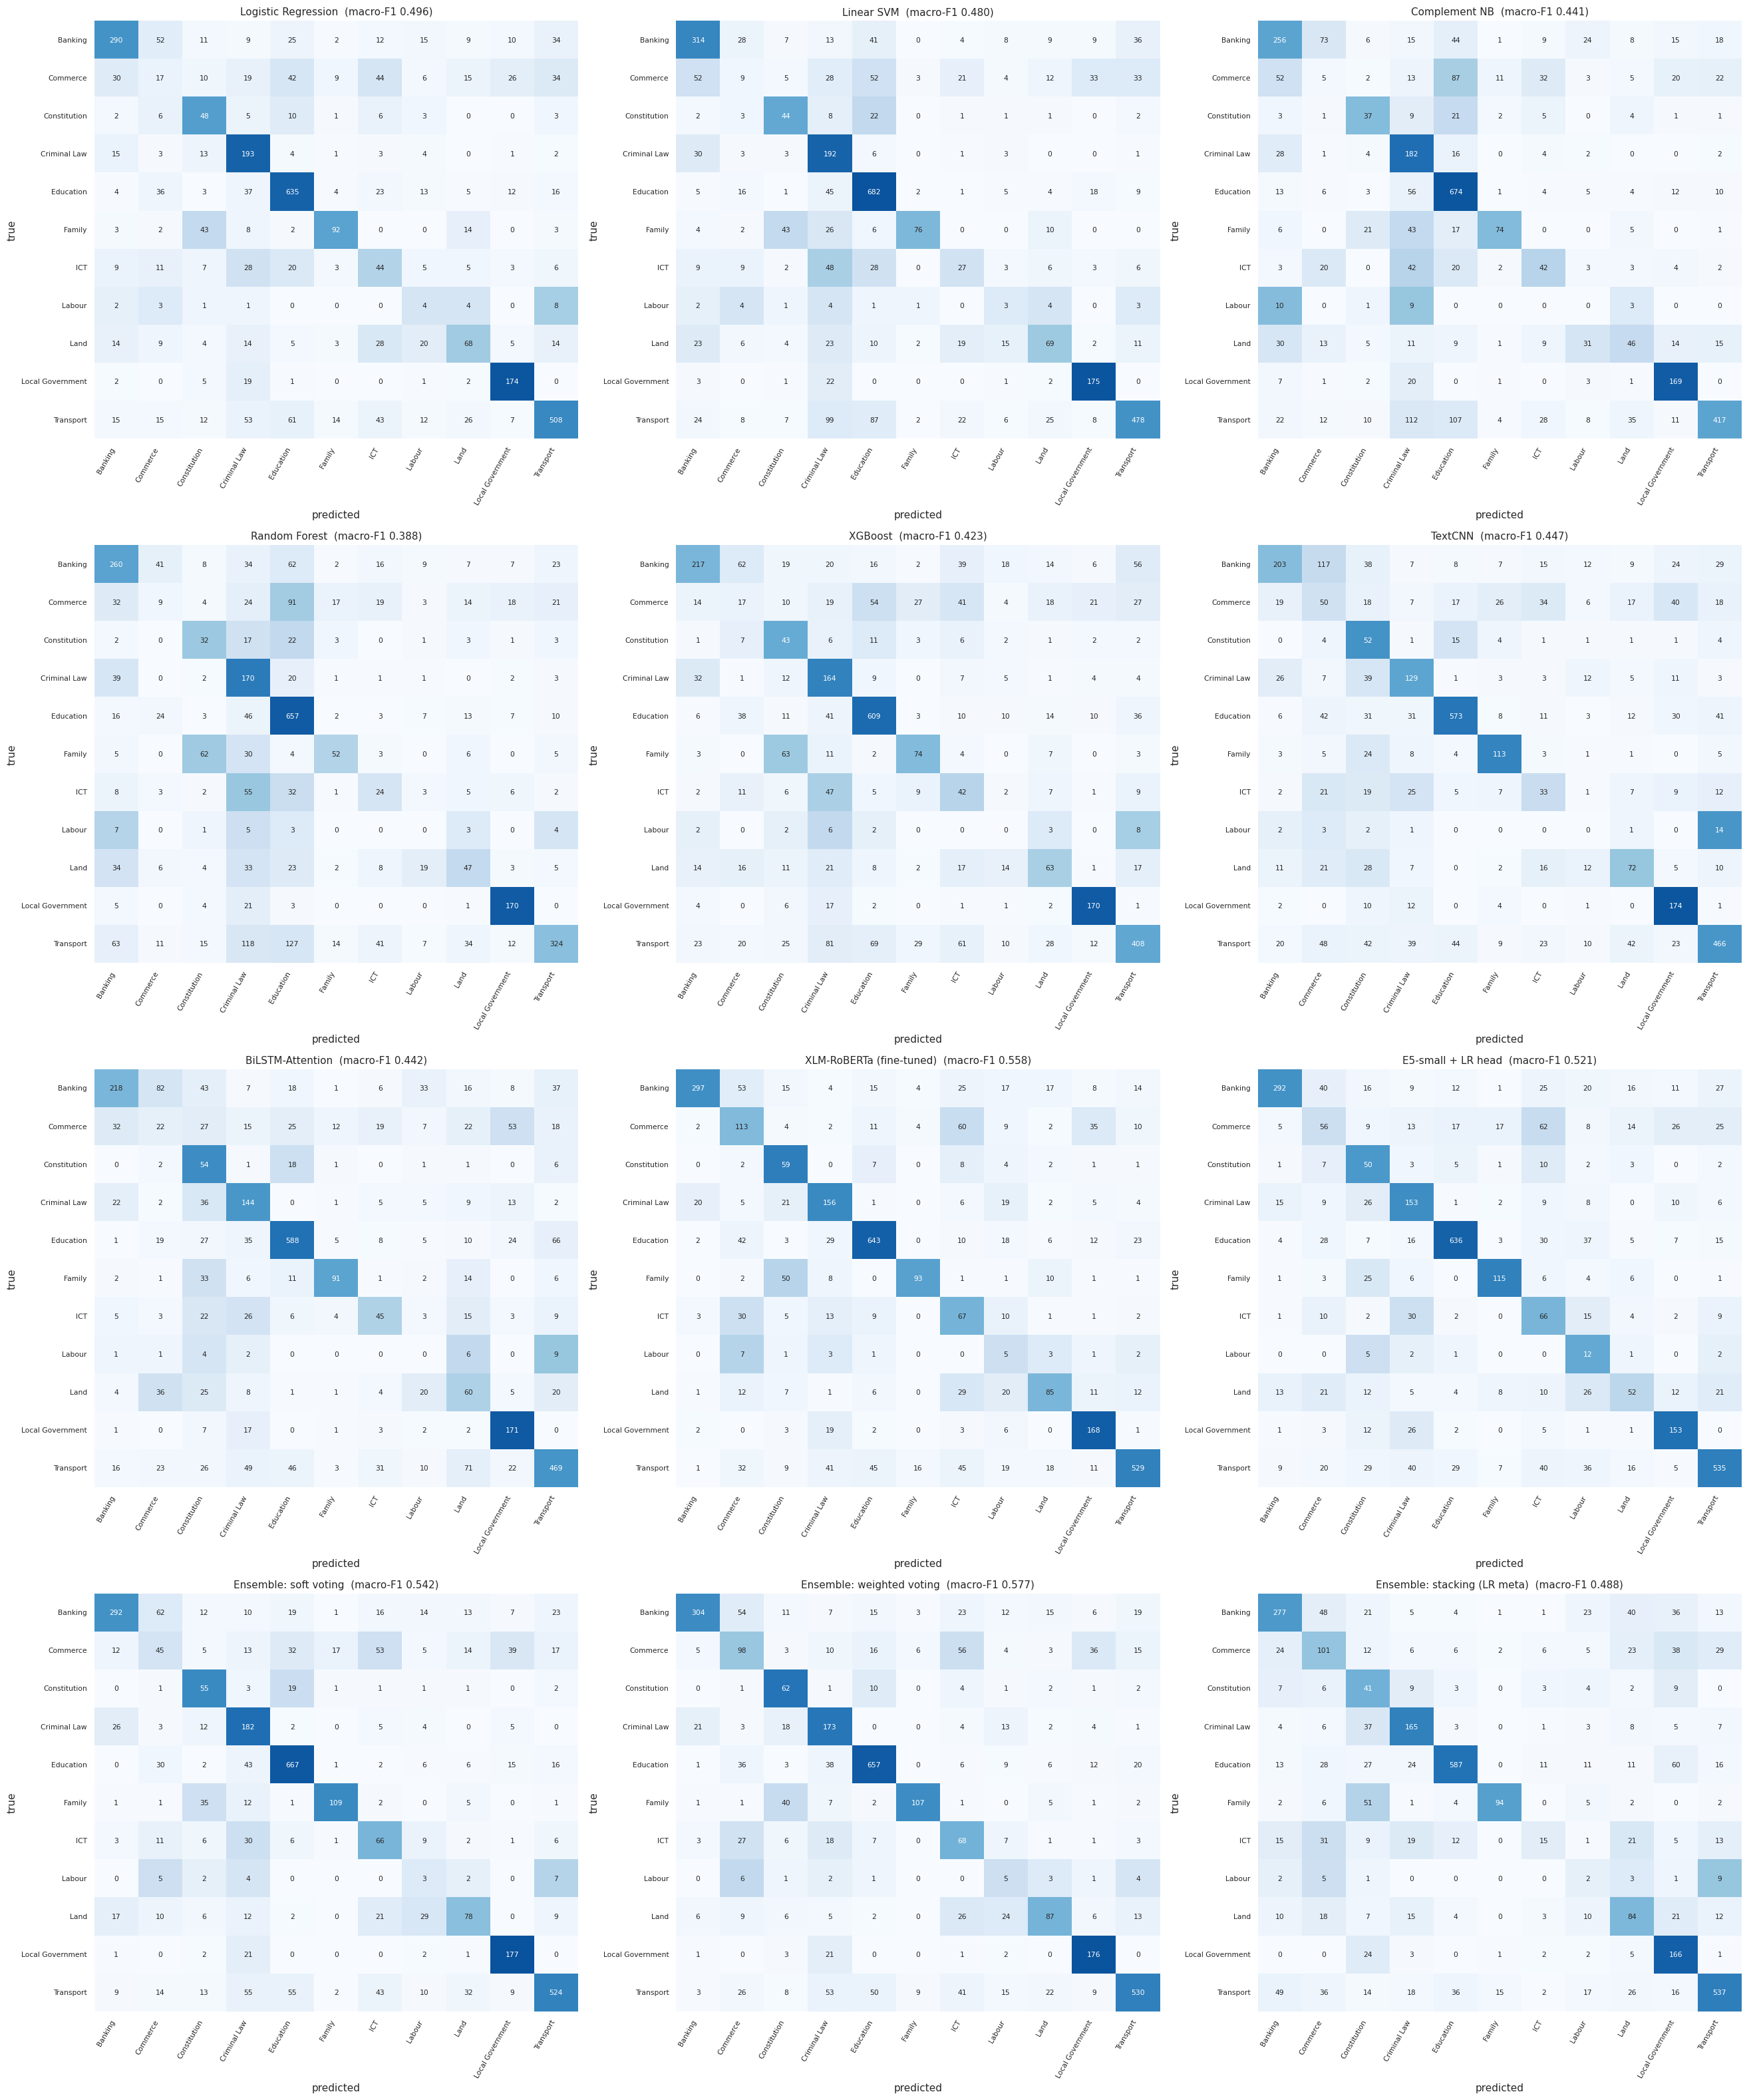

In [21]:
# 13.2 Confusion matrices: best ML · best DL · best ensemble, then every model
best = lambda fam: max((n for n, r in RESULTS.items() if r['family'] == fam), key=lambda n: RESULTS[n]['f1_macro'])
trio = [best('ML'), best('DL'), best('Ensemble')]
fig, ax = plt.subplots(1, 3, figsize=(24, 7.2))
for a, n in zip(ax, trio): plot_cm(RESULTS[n]['P_test'], f'{n}\nmacro-F1 = {RESULTS[n]["f1_macro"]:.3f}', ax=a)
savefig('confusion_matrices_best')

names = list(RESULTS); rows_n = math.ceil(len(names) / 3)
fig, ax = plt.subplots(rows_n, 3, figsize=(24, 7.2 * rows_n)); ax = np.atleast_2d(ax)
for k, a in enumerate(ax.ravel()):
    if k < len(names): plot_cm(RESULTS[names[k]]['P_test'], f'{names[k]}  (macro-F1 {RESULTS[names[k]]["f1_macro"]:.3f})', ax=a)
    else: a.axis('off')
savefig('confusion_matrices_all_models')

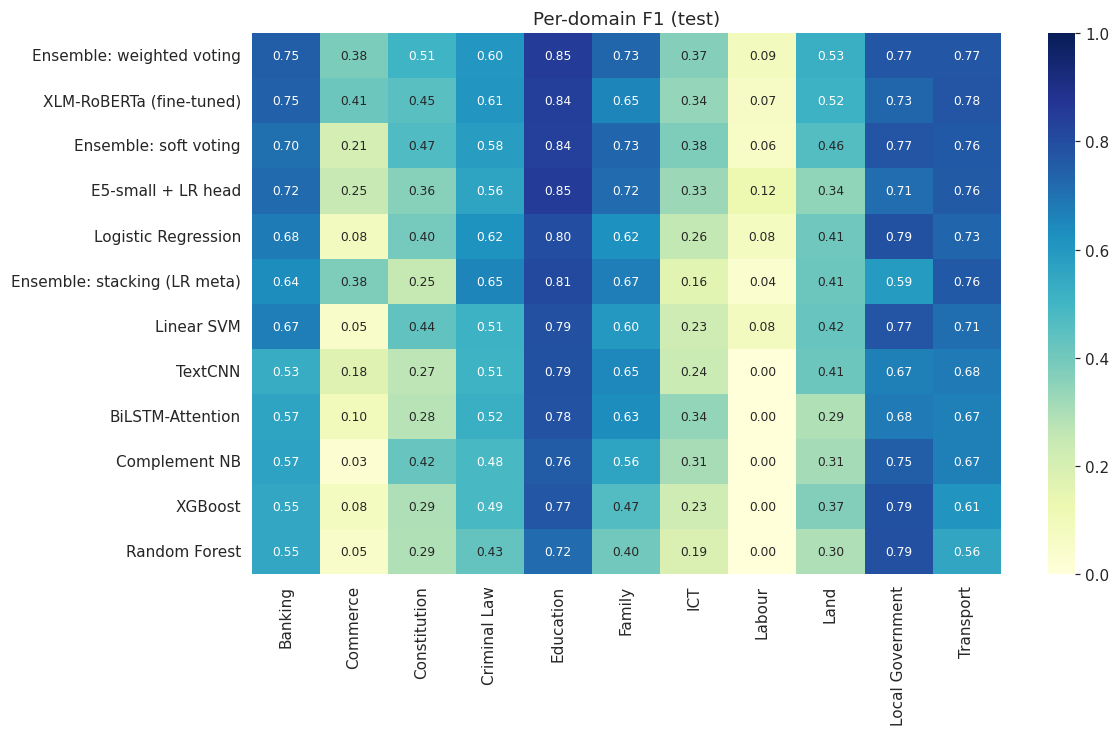

Ensemble: weighted voting: macro-F1 by language -> {'bn': 0.573, 'en': 0.517}
McNemar (exact) Ensemble: weighted voting vs XLM-RoBERTa (fine-tuned): ensemble-only correct=111, single-only correct=59, p=0.0001


,true domain,predicted as,sections
0,"Commerce, Consumer & Companies","ICT, Media & Intellectual Property",56
1,"Banking, Finance & Tax","Commerce, Consumer & Companies",54
2,"Transport, Energy & Infrastructure",Criminal Law & Policing,53
3,"Transport, Energy & Infrastructure","Education, Health & Environment",50
4,"Transport, Energy & Infrastructure","ICT, Media & Intellectual Property",41
5,Family & Personal Law,"Constitution, Courts & Procedure",40
6,"Education, Health & Environment",Criminal Law & Policing,38
7,"Education, Health & Environment","Commerce, Consumer & Companies",36


,title_en,num,label,predicted
0,"The Public Servants (Inquiries) Act, 1850",1,Local Government & Administration,"Constitution, Courts & Procedure"
1,"The Public Servants (Inquiries) Act, 1850",2,Local Government & Administration,Criminal Law & Policing
2,"The Public Servants (Inquiries) Act, 1850",3,Local Government & Administration,Criminal Law & Policing
3,"The Public Servants (Inquiries) Act, 1850",4,Local Government & Administration,Criminal Law & Policing
4,"The Public Servants (Inquiries) Act, 1850",5,Local Government & Administration,Criminal Law & Policing
5,"The Public Servants (Inquiries) Act, 1850",6,Local Government & Administration,Criminal Law & Policing
6,"The Public Servants (Inquiries) Act, 1850",7,Local Government & Administration,Criminal Law & Policing
7,"The Public Servants (Inquiries) Act, 1850",8,Local Government & Administration,Criminal Law & Policing


In [22]:
# 13.3 Per-class F1 heat-map, per-language performance, paired significance, hardest confusions
from scipy.stats import binomtest
pc = pd.DataFrame({n: f1_score(yte, r['P_test'].argmax(1), average=None, labels=range(C)) for n, r in RESULTS.items()}, index=[SHORT[c] for c in CLASSES]).T
fig, ax = plt.subplots(figsize=(11, 0.4 * len(pc) + 2)); sns.heatmap(pc.loc[tab.model], annot=True, fmt='.2f', cmap='YlGnBu', ax=ax, vmin=0, vmax=1, annot_kws={'size': 8})
ax.set_title('Per-domain F1 (test)'); savefig('per_class_f1_heatmap')

top_ens = best('Ensemble'); Pbest = RESULTS[top_ens]['P_test']; pred = Pbest.argmax(1)
lang_f1 = {l: f1_score(yte[te.lang.values == l], pred[te.lang.values == l], average='macro') for l in ['bn', 'en'] if (te.lang.values == l).any()}
print(f'{top_ens}: macro-F1 by language ->', {k: round(v, 3) for k, v in lang_f1.items()})

best_single = max((n for n, r in RESULTS.items() if r['family'] in ('ML', 'DL')), key=lambda n: RESULTS[n]['f1_macro'])
ca, cb = pred == yte, RESULTS[best_single]['P_test'].argmax(1) == yte
b_, c_ = int((ca & ~cb).sum()), int((~ca & cb).sum())
p = binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
print(f'McNemar (exact) {top_ens} vs {best_single}: ensemble-only correct={b_}, single-only correct={c_}, p={p:.4f}')

conf = collections.Counter((CLASSES[a], CLASSES[b]) for a, b in zip(yte, pred) if a != b).most_common(8)
display(pd.DataFrame([(a, b, n) for (a, b), n in conf], columns=['true domain', 'predicted as', 'sections']))
wrong = te[pred != yte].assign(predicted=[CLASSES[i] for i in pred[pred != yte]])[['title_en', 'num', 'label', 'predicted']].head(8)
display(wrong)

,model,n,accuracy,macro_F1
3,Ensemble: weighted voting,383,0.621,0.606
2,XLM-RoBERTa (fine-tuned),383,0.611,0.600
1,Logistic Regression,383,0.522,0.491
0,Qwen2.5-1.5B (zero-shot),383,0.420,0.416


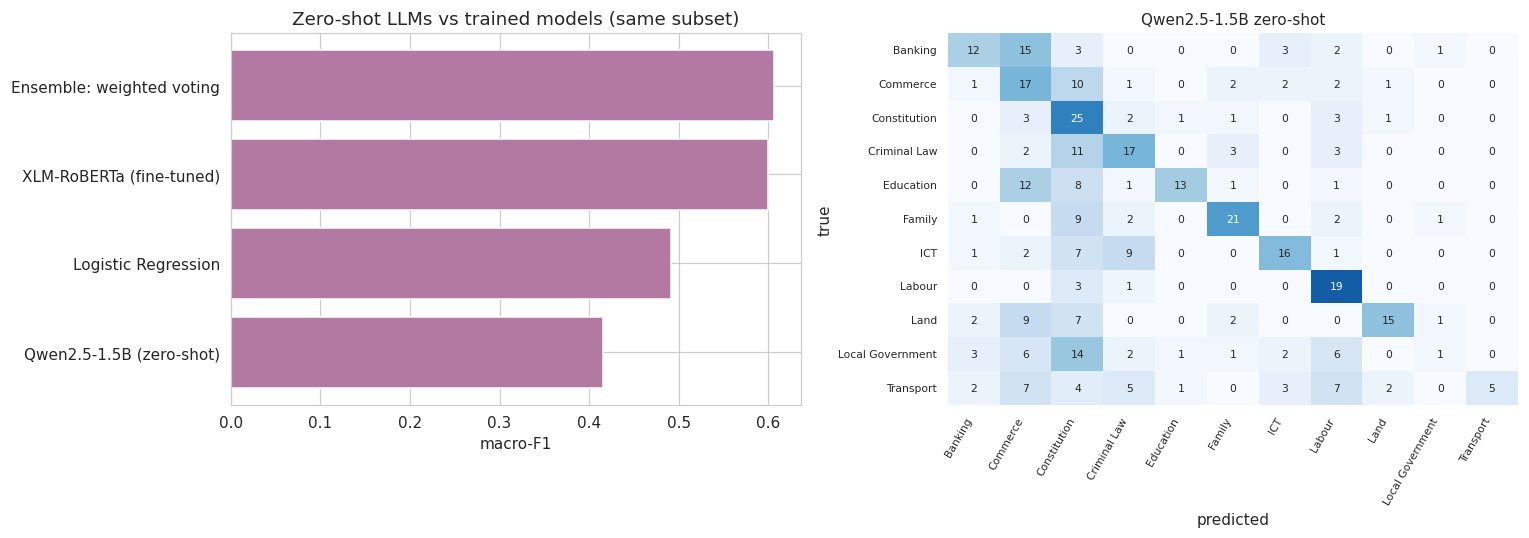

In [23]:
# 13.4 LLM zero-shot vs trained models on the same stratified subset
if len(SUBSET):
    sub = {n: p for n, p in SUBSET.items()}
    for n in [best('ML'), best('DL'), best('Ensemble')]: sub[n] = RESULTS[n]['P_test'][ZS_IDX]
    rows = []
    for n, p in sub.items():
        y = yte[ZS_IDX][:len(p)]; rows.append(dict(model=n, n=len(p), accuracy=accuracy_score(y, p.argmax(1)), macro_F1=f1_score(y, p.argmax(1), average='macro')))
    d = pd.DataFrame(rows).sort_values('macro_F1', ascending=False); display(d.round(3)); d.to_csv(OUT / 'results_llm_zero_shot_subset.csv', index=False)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].barh(d.model[::-1], d.macro_F1[::-1], color='#B279A2'); ax[0].set_title('Zero-shot LLMs vs trained models (same subset)'); ax[0].set_xlabel('macro-F1')
    q = SUBSET.get('Qwen2.5-1.5B (zero-shot)')
    if q is not None: plot_cm(q, 'Qwen2.5-1.5B zero-shot', ax=ax[1], y=yte[ZS_IDX])
    savefig('llm_zero_shot')
else:
    print('No LLM results (USE_HF=0 / FAST_DEBUG).')

## 14 · Retrieval-Augmented Generation — four architectures
```
 question ─► ① SPARSE  BM25 over stemmed tokens ───────────────────────────────┐
          ├► ② DENSE   multilingual-E5-small embeddings + FAISS (cosine) ──────┤► top-k sections ─► LLM answer + [S1..S4] citations
          ├► ③ HYBRID  reciprocal-rank fusion (BM25 + dense, k = 60) ──────────┤
          └► ④ HYBRID + RE-RANK  top-20 of ③ re-scored by Qwen2.5 (Yes/No) ────┘
```
**Retrieval unit:** one statute section = *Act title + section text* (the section **heading is deliberately not indexed**, so the synthetic benchmark below cannot be solved by string-matching its own label).

**Evaluation sets**
* **Curated** — 15 everyday legal questions × (Bengali, English), gold sections identified from the official text (to be reviewed by a lawyer), see `backend/data/eval_set.json`.
* **Synthetic EN→EN** — query = English heading of an English-language Act → gold = that section.
* **Synthetic BN→BN** — query = Bengali heading → Bengali section.
* **Synthetic EN→BN (cross-lingual)** — English heading (machine translation) → section whose text exists **only in Bengali**: lexical matching cannot work, multilingual embeddings can.

In [24]:
docs = raw[(raw.text_bn.str.len() + raw.text_en.str.len()) > 0].copy()
docs['text'] = np.where(docs.text_bn != '', docs.text_bn, docs.text_en)
docs = docs[docs.text.str.len() >= 60].reset_index(drop=True)
docs['title'] = np.where(docs.title_en != '', docs.title_en, docs.title_bn)
docs['doc'] = docs.title + ' | ' + docs.text.str[:1200]
norm_num = lambda n: str(n or '').translate(BN2EN).lower().strip()
docs['key'] = list(zip(docs.act_id, docs.num.map(norm_num)))
print(f'{len(docs):,} retrievable sections')

EVAL_SET = {
 "in_corpus": [
  {
   "id": "fir",
   "en": "The police station refuses to take my complaint. How can I file an FIR?",
   "bn": "থানা আমার অভিযোগ নিচ্ছে না। আমি কীভাবে এজাহার (এফআইআর) দায়ের করতে পারি?",
   "gold": [
    {
     "act": 75,
     "sections": [
      "154"
     ]
    }
   ]
  },
  {
   "id": "bail",
   "en": "Can I get bail after being arrested for a non-bailable offence?",
   "bn": "অজামিনযোগ্য অপরাধে গ্রেপ্তার হলে কি জামিন পাওয়া যায়?",
   "gold": [
    {
     "act": 75,
     "sections": [
      "496",
      "497"
     ]
    }
   ]
  },
  {
   "id": "arrest",
   "en": "When can the police arrest a person without a warrant?",
   "bn": "কখন পুলিশ ওয়ারেন্ট ছাড়া কাউকে গ্রেপ্তার করতে পারে?",
   "gold": [
    {
     "act": 75,
     "sections": [
      "54"
     ]
    }
   ]
  },
  {
   "id": "theft",
   "en": "What is the punishment for theft?",
   "bn": "চুরির শাস্তি কী?",
   "gold": [
    {
     "act": 11,
     "sections": [
      "378",
      "379"
     ]
    }
   ]
  },
  {
   "id": "cheating",
   "en": "Someone cheated me and took my money. What is the punishment for cheating?",
   "bn": "একজন আমাকে ঠকিয়ে টাকা নিয়েছে। প্রতারণার শাস্তি কী?",
   "gold": [
    {
     "act": 11,
     "sections": [
      "417",
      "420"
     ]
    }
   ]
  },
  {
   "id": "threat",
   "en": "A person is threatening to harm me and my family. Is that a crime?",
   "bn": "একজন আমাকে ও আমার পরিবারকে ক্ষতির হুমকি দিচ্ছে। এটা কি অপরাধ?",
   "gold": [
    {
     "act": 11,
     "sections": [
      "503",
      "506"
     ]
    }
   ]
  },
  {
   "id": "rent",
   "en": "My landlord raised the rent without notice and wants to evict me.",
   "bn": "বাড়িওয়ালা নোটিশ ছাড়া ভাড়া বাড়িয়েছেন এবং আমাকে উচ্ছেদ করতে চান।",
   "gold": [
    {
     "act": 748,
     "sections": [
      "7",
      "18"
     ]
    }
   ]
  },
  {
   "id": "dowry",
   "en": "My in-laws demand dowry. What does the law say?",
   "bn": "শ্বশুরবাড়ির লোকজন যৌতুক দাবি করছে। আইনে কী বলে?",
   "gold": [
    {
     "act": 1256,
     "sections": [
      "3",
      "4"
     ]
    }
   ]
  },
  {
   "id": "dv",
   "en": "My husband beats me at home. What legal protection can I get?",
   "bn": "স্বামী আমাকে ঘরে মারধর করে। আমি আইনি কী সুরক্ষা পেতে পারি?",
   "gold": [
    {
     "act": 1063,
     "sections": [
      "11",
      "13",
      "14"
     ]
    }
   ]
  },
  {
   "id": "talaq",
   "en": "How does a Muslim man divorce his wife under the law (talaq)?",
   "bn": "আইন অনুযায়ী তালাক দেওয়ার নিয়ম কী?",
   "gold": [
    {
     "act": 305,
     "sections": [
      "7"
     ]
    }
   ]
  },
  {
   "id": "dower",
   "en": "What happens if the nikah nama does not say how the dower will be paid?",
   "bn": "কাবিননামায় দেনমোহর পরিশোধের নিয়ম না থাকলে কী হবে?",
   "gold": [
    {
     "act": 305,
     "sections": [
      "10"
     ]
    }
   ]
  },
  {
   "id": "cheque",
   "en": "The cheque I received from a customer bounced. What can I do?",
   "bn": "আমার পাওয়া চেকটি ব্যাংকে ডিজঅনার হয়েছে। আমি কী করতে পারি?",
   "gold": [
    {
     "act": 46,
     "sections": [
      "138"
     ]
    }
   ]
  },
  {
   "id": "maternity",
   "en": "Is a female worker entitled to paid maternity leave?",
   "bn": "নারী শ্রমিকের মাতৃত্বকালীন ছুটি ও সুবিধা কি আইনে আছে?",
   "gold": [
    {
     "act": 952,
     "sections": [
      "46"
     ]
    }
   ]
  },
  {
   "id": "mrp",
   "en": "The shopkeeper charged more than the MRP printed on the product.",
   "bn": "দোকানদার পণ্যের গায়ে লেখা এমআরপির চেয়ে বেশি দাম নিয়েছে।",
   "gold": [
    {
     "act": 1014,
     "sections": [
      "40"
     ]
    }
   ]
  },
  {
   "id": "heirs",
   "en": "What share of my father's property does a daughter get under Muslim law?",
   "bn": "মুসলিম আইনে বাবার সম্পত্তিতে মেয়ের অংশ কত?",
   "gold": [
    {
     "act": 173,
     "sections": [
      "2"
     ]
    }
   ]
  }
 ],
 "out_of_corpus": [
  {
   "id": "weather",
   "en": "What is the weather in Chattogram today?",
   "bn": "আজ চট্টগ্রামের আবহাওয়া কেমন?"
  },
  {
   "id": "cricket",
   "en": "Who won the cricket match yesterday?",
   "bn": "গতকালের ক্রিকেট ম্যাচ কে জিতেছে?"
  },
  {
   "id": "foreign",
   "en": "What is the penalty for drunk driving in California?",
   "bn": "ক্যালিফোর্নিয়ায় মাতাল অবস্থায় গাড়ি চালানোর শাস্তি কী?"
  }
 ]
}

34,952 retrievable sections


In [25]:
# ---- build query sets --------------------------------------------------------------------------------------------
key2idx = collections.defaultdict(list)
for i, k in enumerate(docs.key): key2idx[k].append(i)
curated, ooc = [], []
for q in EVAL_SET['in_corpus']:
    rel = {i for g in q['gold'] for s in g['sections'] for i in key2idx.get((g['act'], norm_num(s)), [])}
    for lang in ('en', 'bn'):
        if rel: curated.append(dict(id=q['id'], lang=lang, text=q[lang], rel=rel))
for q in EVAL_SET['out_of_corpus']:
    for lang in ('en', 'bn'): ooc.append(dict(id=q['id'], lang=lang, text=q[lang]))
OOC_GENERIC = ['best recipe for chicken biryani', 'how to learn guitar quickly', 'who won the football world cup', 'what is the capital of Japan', 'how to lose weight fast',
               'latest smartphone camera comparison', 'explain photosynthesis to a child', 'tips for a job interview', 'how far is the moon', 'translate hello into French',
               'বিরিয়ানির সহজ রেসিপি', 'গিটার শেখার সহজ উপায়', 'বিশ্বকাপ ফুটবল কে জিতেছে', 'জাপানের রাজধানী কোথায়', 'দ্রুত ওজন কমানোর উপায়', 'চাকরির ইন্টারভিউয়ের টিপস', 'চাঁদ কত দূরে', 'সালাদ বানানোর নিয়ম']
ooc += [dict(id=f'gen{i}', lang='bn' if bn_ratio(t) > 0.5 else 'en', text=t) for i, t in enumerate(OOC_GENERIC)]

GENERIC = re.compile(r'short title|definition|interpretation|commencement|repeal|savings|rules|extent|সংক্ষিপ্ত|সংজ্ঞা|প্রবর্তন|রহিত|বিধি', re.I)
cnt_en, cnt_bn = docs.heading_en.value_counts(), docs.heading_bn.value_counts()
N_SYN = 25 if FAST_DEBUG else 150
rs = np.random.RandomState(SEED)
def sample_syn(mask, head_col, name, cnt):
    d = docs[mask & (docs[head_col].str.len().between(12, 110)) & (docs.text.str.len() >= 200)]
    d = d[~d[head_col].str.contains(GENERIC)]; d = d[d[head_col].map(cnt) <= 2]
    d = d.sample(min(N_SYN, len(d)), random_state=SEED)
    return [dict(id=f'{name}-{i}', lang='bn' if head_col == 'heading_bn' else 'en', text=r[head_col], rel={i}) for i, r in d.iterrows()]
is_bn_doc = docs.text.map(lambda s: bn_ratio(s) >= 0.5)
SYN = {'Synthetic EN→EN': sample_syn(~is_bn_doc, 'heading_en', 'ee', cnt_en),
       'Synthetic BN→BN': sample_syn(is_bn_doc & (docs.heading_bn != ''), 'heading_bn', 'bb', cnt_bn),
       'Synthetic EN→BN (cross-lingual)': sample_syn(is_bn_doc & (docs.heading_en != ''), 'heading_en', 'eb', cnt_en)}
QSETS = {'Curated (30 Q)': curated, **SYN}
print({k: len(v) for k, v in QSETS.items()}, '· out-of-scope queries:', len(ooc))

if FAST_DEBUG:     # keep the smoke test small: gold documents + 2,500 random sections
    need = set().union(*[q['rel'] for s in QSETS.values() for q in s])
    keep = sorted(need | set(np.random.RandomState(0).choice(len(docs), 2500, replace=False)))
    remap = {o: n for n, o in enumerate(keep)}
    docs = docs.iloc[keep].reset_index(drop=True)
    for s in QSETS.values():
        for q in s: q['rel'] = {remap[i] for i in q['rel']}

{'Curated (30 Q)': 30, 'Synthetic EN→EN': 150, 'Synthetic BN→BN': 150, 'Synthetic EN→BN (cross-lingual)': 150} · out-of-scope queries: 24


### 14.1 Indexes: sparse (BM25) and dense (E5 + FAISS)

In [26]:
import faiss
from rank_bm25 import BM25Okapi
t0 = time.time()
doc_tokens = [tokenise(t) for t in docs.doc]
bm25 = BM25Okapi(doc_tokens)
print(f'BM25 index: {len(doc_tokens):,} sections, avg {np.mean([len(t) for t in doc_tokens]):.0f} tokens ({time.time() - t0:.0f}s)')

if USE_HF:
    from sentence_transformers import SentenceTransformer
    if 'e5' not in globals():
        e5 = SentenceTransformer('intfloat/multilingual-e5-small', device='cuda' if GPU else 'cpu'); e5.max_seq_length = 256
    DENSE_NAME = 'multilingual-E5-small'
    cache = OUT / 'e5_docs.npy'
    if cache.exists() and np.load(cache).shape[0] == len(docs): D = np.load(cache)
    else:
        D = e5.encode(['passage: ' + t for t in docs.doc], batch_size=128, normalize_embeddings=True, show_progress_bar=True, convert_to_numpy=True).astype('float32'); np.save(cache, D)
    embed_queries = lambda qs: e5.encode(['query: ' + q for q in qs], normalize_embeddings=True, convert_to_numpy=True).astype('float32')
else:   # smoke-test stand-in: LSA (no cross-lingual ability) so that the pipeline code is still exercised
    DENSE_NAME = 'LSA stand-in (USE_HF=0)'
    _tf = TfidfVectorizer(max_features=30000, sublinear_tf=True, token_pattern=r'\S+').fit([' '.join(t) for t in doc_tokens])
    _sv = TruncatedSVD(n_components=96, random_state=SEED).fit(_tf.transform([' '.join(t) for t in doc_tokens]))
    _nz = lambda M: (M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-9)).astype('float32')
    D = _nz(_sv.transform(_tf.transform([' '.join(t) for t in doc_tokens])))
    embed_queries = lambda qs: _nz(_sv.transform(_tf.transform([' '.join(tokenise(q)) for q in qs])))
index = faiss.IndexFlatIP(D.shape[1]); index.add(D)
print(f'dense index: {DENSE_NAME}, {D.shape[0]:,} x {D.shape[1]} ({time.time() - t0:.0f}s)')

def bm25_scores(q): return bm25.get_scores(tokenise(q))
def topk(s, k):
    k = min(k, len(s)); idx = np.argpartition(-s, k - 1)[:k]; return idx[np.argsort(-s[idx])].tolist()
def sparse_search(q, k=10): return topk(bm25_scores(q), k)
def dense_search(q, k=10): return index.search(embed_queries([q]), k)[1][0].tolist()
def rrf(lists, k=60, n=100):
    sc = collections.defaultdict(float)
    for L in lists:
        for r, i in enumerate(L): sc[i] += 1.0 / (k + r + 1)
    return sorted(sc, key=sc.get, reverse=True)[:n]
def hybrid_search(q, k=10): return rrf([sparse_search(q, 100), dense_search(q, 100)])[:k]

BM25 index: 34,952 sections, avg 57 tokens (10s)


Batches:   0%|          | 0/274 [00:00<?, ?it/s]

dense index: multilingual-E5-small, 34,952 x 384 (156s)


### 14.2 Re-ranker (RAG ④)
With `USE_HF=1` the re-ranker is **Qwen2.5-1.5B-Instruct** scoring `logit(Yes) − logit(No)` for *“does this passage contain the information needed to answer the query?”* on the top-20 hybrid candidates. In smoke-test mode a lexical-overlap stand-in is used.

In [27]:
def ensure_qwen():
    global qtok, qllm
    if 'qllm' in globals() and qllm is not None: return
    from transformers import AutoTokenizer, AutoModelForCausalLM
    qtok = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-1.5B-Instruct'); qtok.padding_side = 'left'
    qllm = AutoModelForCausalLM.from_pretrained('Qwen/Qwen2.5-1.5B-Instruct', torch_dtype=torch.float16 if GPU else torch.float32, device_map='auto' if GPU else None).eval()

if USE_HF:
    ensure_qwen()
    from transformers import AutoTokenizer
    YES, NO = qtok.encode('Yes', add_special_tokens=False)[0], qtok.encode('No', add_special_tokens=False)[0]
    def _chat(user, system='You are an expert in Bangladeshi law.'):
        return qtok.apply_chat_template([{'role': 'system', 'content': system}, {'role': 'user', 'content': user}], tokenize=False, add_generation_prompt=True)
    @torch.no_grad()
    def relevance(q, passages, bs=10):
        out = []
        for i in range(0, len(passages), bs):
            ps = [_chat(f'Query: {q}\n\nPassage: {p[:500]}\n\nDoes the passage contain the information needed to answer the query? Answer Yes or No.') for p in passages[i:i + bs]]
            enc = qtok(ps, return_tensors='pt', padding=True).to(qllm.device)
            lg = qllm(**enc).logits[:, -1, :].float(); out += (lg[:, YES] - lg[:, NO]).cpu().tolist()
        return np.array(out)
    RERANKER = 'Qwen2.5-1.5B (Yes/No logit)'
else:
    def relevance(q, passages):
        qt = set(tokenise(q)); return np.array([len(qt & set(tokenise(p[:500]))) / (1 + len(qt)) for p in passages])
    RERANKER = 'lexical-overlap stand-in (USE_HF=0)'

def rerank_search(q, k=10, n_cand=20):
    cands = hybrid_search(q, n_cand)
    order = np.argsort(-relevance(q, [docs.doc[i] for i in cands]))
    return [cands[j] for j in order][:k]
RAG_TYPES = {'① Sparse BM25': sparse_search, '② Dense (' + DENSE_NAME.split(' ')[0] + ')': dense_search, '③ Hybrid RRF': hybrid_search, '④ Hybrid + re-rank': rerank_search}
print('re-ranker:', RERANKER)

re-ranker: Qwen2.5-1.5B (Yes/No logit)


### 14.3 Retrieval benchmark
Metrics per query set: **Hit@1/3/5/10**, **Recall@10**, **MRR@10**, **nDCG@10**, and mean latency per query. Curated questions have several gold sections, so Recall@10 is the share of gold sections found.

Curated (30 Q)                    ① Sparse BM25              Hit@5=0.200  MRR=0.162  43 ms
Curated (30 Q)                    ② Dense (multilingual-E5-small) Hit@5=0.400  MRR=0.289  20 ms
Curated (30 Q)                    ③ Hybrid RRF               Hit@5=0.333  MRR=0.245  62 ms
Curated (30 Q)                    ④ Hybrid + re-rank         Hit@5=0.333  MRR=0.209  1769 ms
Synthetic EN→EN                   ① Sparse BM25              Hit@5=0.613  MRR=0.499  31 ms
Synthetic EN→EN                   ② Dense (multilingual-E5-small) Hit@5=0.600  MRR=0.478  16 ms
Synthetic EN→EN                   ③ Hybrid RRF               Hit@5=0.647  MRR=0.536  55 ms
Synthetic EN→EN                   ④ Hybrid + re-rank         Hit@5=0.607  MRR=0.466  843 ms
Synthetic BN→BN                   ① Sparse BM25              Hit@5=0.600  MRR=0.456  34 ms
Synthetic BN→BN                   ② Dense (multilingual-E5-small) Hit@5=0.407  MRR=0.296  16 ms
Synthetic BN→BN                   ③ Hybrid RRF               Hit@5=0.627

,query_set,rag,n,Hit@1,Hit@3,Hit@5,Hit@10,Recall@10,MRR@10,nDCG@10,ms/query
0,Curated (30 Q),① Sparse BM25,30,0.133,0.167,0.200,0.267,0.233,0.162,0.176,42.685
1,Curated (30 Q),② Dense (multilingual-E5-small),30,0.200,0.367,0.400,0.433,0.394,0.289,0.297,20.417
2,Curated (30 Q),③ Hybrid RRF,30,0.167,0.300,0.333,0.400,0.356,0.245,0.257,61.683
3,Curated (30 Q),④ Hybrid + re-rank,30,0.133,0.267,0.333,0.400,0.339,0.209,0.222,1769.428
4,Synthetic EN→EN,① Sparse BM25,150,0.413,0.553,0.613,0.667,0.667,0.499,0.540,31.050
5,Synthetic EN→EN,② Dense (multilingual-E5-small),150,0.400,0.520,0.600,0.647,0.647,0.478,0.519,16.418
6,Synthetic EN→EN,③ Hybrid RRF,150,0.447,0.607,0.647,0.700,0.700,0.536,0.576,54.944
7,Synthetic EN→EN,④ Hybrid + re-rank,150,0.373,0.507,0.607,0.693,0.693,0.466,0.520,842.519
8,Synthetic BN→BN,① Sparse BM25,150,0.353,0.540,0.600,0.667,0.667,0.456,0.507,34.369
9,Synthetic BN→BN,② Dense (multilingual-E5-small),150,0.200,0.333,0.407,0.513,0.513,0.296,0.348,16.487


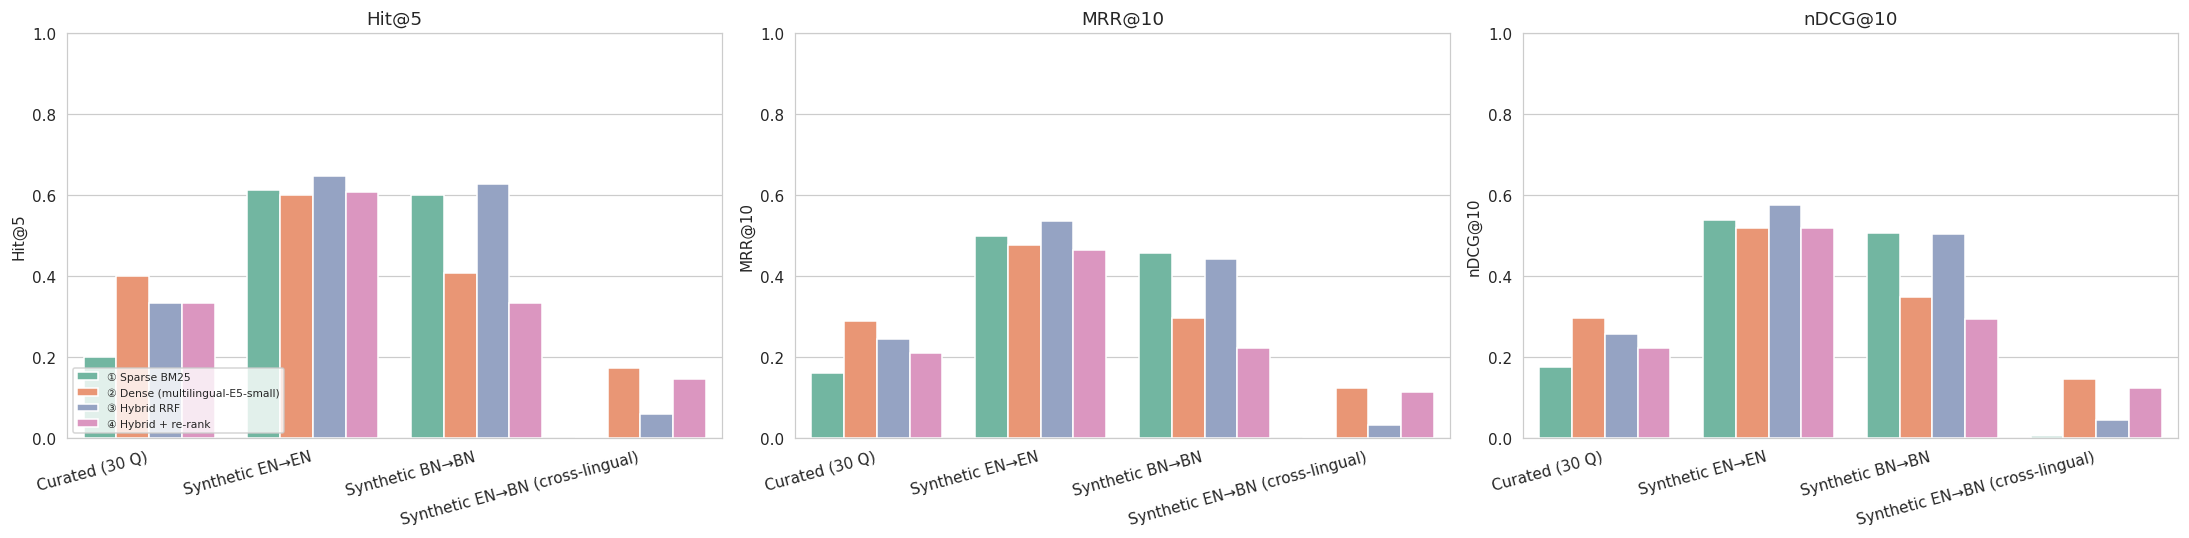

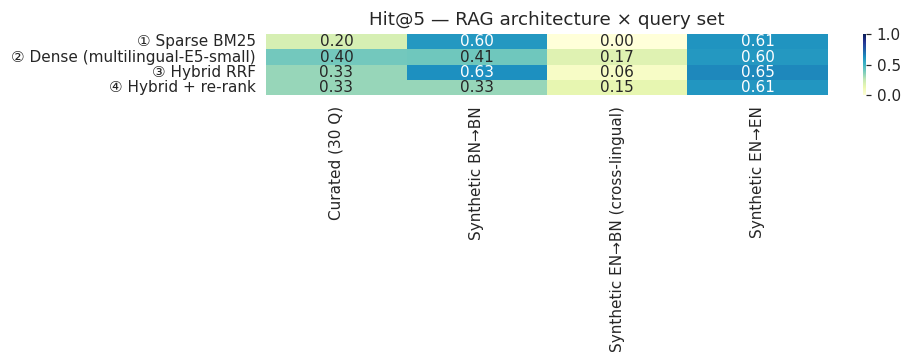

In [28]:
def evaluate(search_fn, queries, kmax=10):
    hit = {k: [] for k in (1, 3, 5, 10)}; rr, nd, rec = [], [], []; t0 = time.time()
    for q in queries:
        ranked = search_fn(q['text'], kmax); rel = q['rel']
        pos = [r for r, i in enumerate(ranked, 1) if i in rel]
        for k in hit: hit[k].append(float(any(p <= k for p in pos)))
        rr.append(1.0 / pos[0] if pos else 0.0)
        nd.append(sum(1 / math.log2(p + 1) for p in pos) / sum(1 / math.log2(r + 1) for r in range(1, min(len(rel), kmax) + 1)))
        rec.append(len([p for p in pos]) / len(rel))
    return {**{f'Hit@{k}': np.mean(v) for k, v in hit.items()}, 'Recall@10': np.mean(rec), 'MRR@10': np.mean(rr), 'nDCG@10': np.mean(nd),
            'ms/query': 1000 * (time.time() - t0) / len(queries)}

rows = []
for set_name, qs in QSETS.items():
    for rag_name, fn in RAG_TYPES.items():
        if not qs: continue
        rows.append(dict(query_set=set_name, rag=rag_name, n=len(qs), **evaluate(fn, qs)))
        print(f'{set_name:<34}{rag_name:<26} Hit@5={rows[-1]["Hit@5"]:.3f}  MRR={rows[-1]["MRR@10"]:.3f}  {rows[-1]["ms/query"]:.0f} ms')
rag_tab = pd.DataFrame(rows); rag_tab.to_csv(OUT / 'results_rag_retrieval.csv', index=False)
display(rag_tab.round(3))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, met in zip(ax, ['Hit@5', 'MRR@10', 'nDCG@10']):
    sns.barplot(data=rag_tab, x='query_set', y=met, hue='rag', ax=a, palette='Set2'); a.set_title(met); a.set_xlabel(''); a.set_ylim(0, 1)
    plt.setp(a.get_xticklabels(), rotation=15, ha='right'); a.legend(fontsize=7, loc='lower left') if met == 'Hit@5' else a.legend().remove()
savefig('rag_retrieval_comparison')
hm = rag_tab.pivot(index='rag', columns='query_set', values='Hit@5')
fig, ax = plt.subplots(figsize=(9, 3.4)); sns.heatmap(hm, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax); ax.set_title('Hit@5 — RAG architecture × query set'); ax.set_ylabel(''); ax.set_xlabel('')
savefig('rag_hit5_heatmap')

Hit@5        MRR@10       
lang                                bn     en     bn     en
rag                                                        
① Sparse BM25                    0.067  0.333  0.067  0.257
② Dense (multilingual-E5-small)  0.133  0.667  0.100  0.477
③ Hybrid RRF                     0.200  0.467  0.083  0.407
④ Hybrid + re-rank               0.067  0.600  0.078  0.341

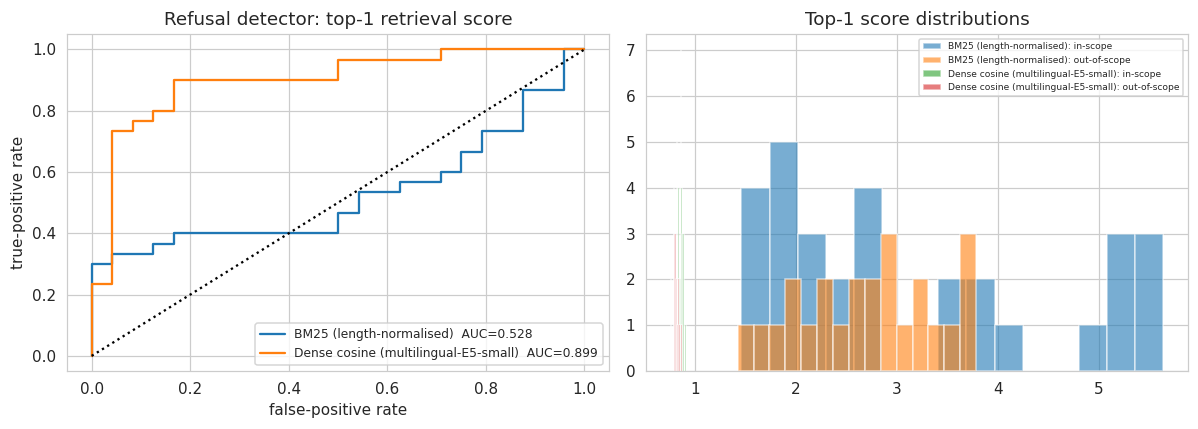

In [29]:
# Curated questions split by language, and out-of-scope detection (can the retriever tell that the corpus does not cover a question?)
from sklearn.metrics import roc_curve, roc_auc_score
by_lang = []
for lang in ('en', 'bn'):
    qs = [q for q in curated if q['lang'] == lang]
    for rag_name, fn in RAG_TYPES.items(): by_lang.append(dict(lang=lang, rag=rag_name, **{k: v for k, v in evaluate(fn, qs).items() if k in ('Hit@5', 'MRR@10')}))
display(pd.DataFrame(by_lang).pivot(index='rag', columns='lang', values=['Hit@5', 'MRR@10']).round(3))

in_scope = [q['text'] for q in curated]; out_scope = [q['text'] for q in ooc]
top_bm25 = lambda qs: [bm25_scores(q).max() / (1 + len(tokenise(q))) for q in qs]
top_dense = lambda qs: [index.search(embed_queries([q]), 1)[0][0][0] for q in qs]
fig, ax = plt.subplots(1, 2, figsize=(11, 4));
for name, f in [('BM25 (length-normalised)', top_bm25), (f'Dense cosine ({DENSE_NAME.split(" ")[0]})', top_dense)]:
    s = np.array(f(in_scope) + f(out_scope)); y = np.array([1] * len(in_scope) + [0] * len(out_scope))
    fpr, tpr, thr = roc_curve(y, s); ax[0].plot(fpr, tpr, label=f'{name}  AUC={roc_auc_score(y, s):.3f}')
    ax[1].hist(s[y == 1], bins=15, alpha=.6, label=f'{name}: in-scope'); ax[1].hist(s[y == 0], bins=15, alpha=.6, label=f'{name}: out-of-scope')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_title('Refusal detector: top-1 retrieval score'); ax[0].set_xlabel('false-positive rate'); ax[0].set_ylabel('true-positive rate'); ax[0].legend(fontsize=8)
ax[1].set_title('Top-1 score distributions'); ax[1].legend(fontsize=6)
savefig('rag_out_of_scope_roc')

## 15 · Generation with LLMs (RAG vs no-RAG)
The best retriever supplies the top-4 sections as numbered sources `[S1]…[S4]`; the LLM must answer **only from them**, in the question's language, and cite the source numbers. A **no-RAG baseline** asks the same model to answer from memory and to name the Act and section.

**Metrics (automatic, no LLM judge):**
* *Citation precision / recall* — cited `[Sx]` that are gold sections (RAG only).
* *Groundedness proxy* — share of answer sentences whose content words are ≥ 50 % covered by the retrieved sources.
* *Section-number accuracy* — answer names the correct section number **and** Act (works for both, shows hallucination without retrieval).

In [30]:
SYSTEM = ('You are a careful legal-information assistant for citizens of Bangladesh. Answer ONLY from the numbered sources. Reply in the language of the question, in short plain paragraphs. '
          'Cite sources like [S1]. If the sources do not answer the question, say that the corpus does not cover it. You are not a lawyer.')
def build_context(ranked, n=4): return '\n\n'.join(f'[S{j + 1}] {docs.title[i]} · Section {docs.num[i]}\n{docs.text[i][:700]}' for j, i in enumerate(ranked[:n]))
def rag_prompt(q, ranked): return f'Sources:\n{build_context(ranked)}\n\nQuestion: {q}'
NO_RAG_SYSTEM = 'You are a legal assistant for Bangladesh. Answer briefly and always name the Act and the section number that applies.'

if USE_HF:
    ensure_qwen()
    @torch.no_grad()
    def qwen_generate(user, system, max_new=220):
        enc = qtok(qtok.apply_chat_template([{'role': 'system', 'content': system}, {'role': 'user', 'content': user}], tokenize=False, add_generation_prompt=True), return_tensors='pt').to(qllm.device)
        out = qllm.generate(**enc, max_new_tokens=max_new, do_sample=False, repetition_penalty=1.05)
        return qtok.decode(out[0, enc['input_ids'].shape[1]:], skip_special_tokens=True).strip()
    GENERATORS = {'Qwen2.5-1.5B-Instruct': qwen_generate}
    if GKEY: GENERATORS['Gemini 2.5 Flash'] = lambda user, system, max_new=220: gemini_call(system + '\n\n' + user) or ''
else:
    print('USE_HF=0: smoke-test generator (echoes the first source) — numbers below are NOT model results')
    GENERATORS = {'smoke-test echo': lambda user, system, max_new=220: ('[S1] ' + (user.split('\n')[2] if user.startswith('Sources') else 'Section 1 of the Act applies.'))}
BEST_RAG = max(RAG_TYPES, key=lambda r: rag_tab[(rag_tab.rag == r) & (rag_tab.query_set == 'Curated (30 Q)')]['MRR@10'].mean())
print('retriever used for generation:', BEST_RAG)

retriever used for generation: ② Dense (multilingual-E5-small)


,llm,mode,questions,citation_precision,citation_hit,groundedness,section_number_accuracy
0,Qwen2.5-1.5B-Instruct,RAG,30,0.1,0.1,0.537,0.167
1,Qwen2.5-1.5B-Instruct,no-RAG,30,NaN,NaN,NaN,0.000


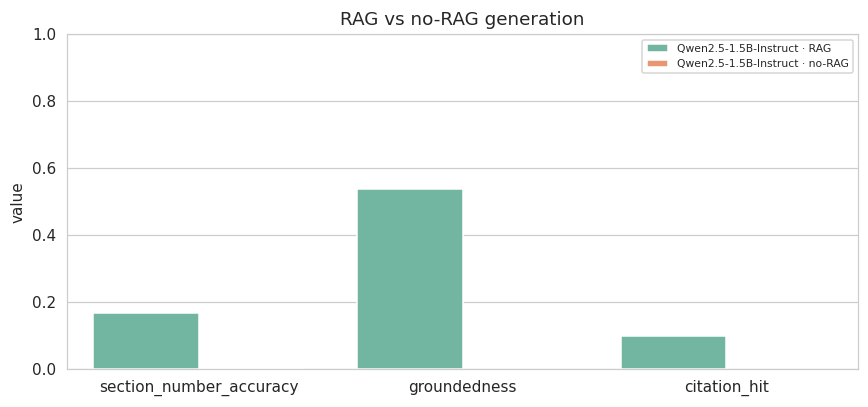


[Qwen2.5-1.5B-Instruct] The police station refuses to take my complaint. How can I file an FIR?
To file an FIR (First Information Report) despite a police station's refusal to accept your complaint, you can follow these steps:

1. **Seek Legal Advice**: Consult a lawyer who specializes in criminal law. They can guide you through the process and help you understand your rights.

2. **File a Written Complaint**: Write a formal complaint detailing the incident. Include as much information as possible, including dates, times, locations, and descriptions of what happened.

3. **Contact the District Magistrate’s Office**: If the police station is unwilling to register the complaint, contact the District Magistrate’s Office. They have the authority to register complaints even if the police station declines to do so.

4. **File a Petition in the High Court**: If the District Magistrate’s Office also refuses to register the complaint, you can file a petition in the High Court. This court has j

In [31]:
CONTENT = lambda s: {w for w in tokenise(s)}
def groundedness(answer, ctx):
    sents = [s for s in re.split(r'(?<=[.!?।])\s+', answer) if len(CONTENT(s)) >= 4]; cc = CONTENT(ctx)
    return float(np.mean([len(CONTENT(s) & cc) / len(CONTENT(s)) >= 0.5 for s in sents])) if sents else 0.0
def section_correct(answer, rel):
    a = answer.translate(BN2EN).lower(); good = False
    for i in rel:
        num = norm_num(docs.num[i]); act_tokens = [t for t in tokenise(docs.title[i]) if len(t) > 3][:4]
        good |= bool(re.search(rf'(?<!\d){re.escape(num)}(?!\d)', a)) and sum(t in tokenise(a) for t in act_tokens) >= max(1, len(act_tokens) // 2)
    return float(good)

N_GEN = 6 if FAST_DEBUG else len(curated)
rows, samples = [], []
for gname, gen in GENERATORS.items():
    for mode in ('RAG', 'no-RAG'):
        cp, cr, gr, sc = [], [], [], []
        for q in curated[:N_GEN]:
            if mode == 'RAG':
                ranked = RAG_TYPES[BEST_RAG](q['text'], 10); ctx = build_context(ranked); ans = gen(rag_prompt(q['text'], ranked), SYSTEM)
                cited = [int(x) - 1 for x in re.findall(r'\[S(\d)\]', ans) if 0 < int(x) <= 4]; cited_docs = {ranked[j] for j in cited if j < len(ranked)}
                cp.append(len(cited_docs & q['rel']) / len(cited_docs) if cited_docs else 0.0); cr.append(float(bool(cited_docs & q['rel'])))
                gr.append(groundedness(ans, ctx))
            else:
                ans = gen(q['text'], NO_RAG_SYSTEM); ctx = ''
            sc.append(section_correct(ans, q['rel']))
            if len(samples) < 6 and mode == 'RAG': samples.append((gname, q['text'], ans))
        rows.append(dict(llm=gname, mode=mode, questions=N_GEN, citation_precision=np.mean(cp) if cp else np.nan, citation_hit=np.mean(cr) if cr else np.nan,
                         groundedness=np.mean(gr) if gr else np.nan, section_number_accuracy=np.mean(sc)))
gen_tab = pd.DataFrame(rows); display(gen_tab.round(3)); gen_tab.to_csv(OUT / 'results_rag_generation.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
gen_tab.melt(id_vars=['llm', 'mode'], value_vars=['section_number_accuracy', 'groundedness', 'citation_hit']).dropna().pipe(
    lambda d: sns.barplot(data=d.assign(group=d.llm + ' · ' + d['mode']), x='variable', y='value', hue='group', ax=ax, palette='Set2'))
ax.set_ylim(0, 1); ax.set_title('RAG vs no-RAG generation'); ax.set_xlabel(''); ax.legend(fontsize=7)
savefig('rag_generation_comparison')
for g, q, a in samples[:3]: print(f'\n[{g}] {q}\n{a}\n' + '-' * 80)

## 16 · Summary & export

In [32]:
best_cls = tab.iloc[0]
print('=' * 78); print('BEST CLASSIFIER :', best_cls.model, f'(macro-F1 {best_cls.macro_F1:.3f}, 95% CI {best_cls.F1_CI_low:.3f}-{best_cls.F1_CI_high:.3f})')
print('BEST RAG        :', rag_tab.groupby('rag')[['Hit@5', 'MRR@10']].mean().round(3).sort_values('MRR@10', ascending=False).head(1).to_dict('index'))
n_of = lambda fam: sum(r['family'] == fam for r in RESULTS.values())
print(f"models        : {n_of('ML')} ML + {n_of('DL')} DL + {len(SUBSET)} zero-shot LLM(s) + Qwen as RAG generator/re-ranker + {n_of('Ensemble')} ensembles")
print('=' * 78)

import joblib, zipfile
art = OUT / 'artifacts'; art.mkdir(exist_ok=True)
joblib.dump({'vec_w': vec_w, 'vec_c': vec_c, 'svd': svd, 'classes': CLASSES}, art / 'vectorisers.joblib')
for n, m in [('logreg', lr), ('linear_svm', svm), ('complement_nb', nb), ('random_forest', rf)]: joblib.dump(m, art / f'{n}.joblib')
xgb.save_model(str(art / 'xgboost.json')); cnn.save(art / 'textcnn.keras'); bilstm.save(art / 'bilstm_attention.keras')
json.dump({'vocab': vocab, 'maxlen': MAXLEN}, open(art / 'dl_vocab.json', 'w'), ensure_ascii=False)
if 'D' in globals(): np.save(art / 'section_embeddings.npy', D.astype('float16'))
with zipfile.ZipFile('legal_ai_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file(): z.write(p)
print('saved -> legal_ai_outputs.zip (figures, CSV tables, models)')
try:
    from google.colab import files; files.download('legal_ai_outputs.zip')
except Exception: pass

BEST CLASSIFIER : Ensemble: weighted voting (macro-F1 0.577, 95% CI 0.472-0.602)
BEST RAG        : {'③ Hybrid RRF': {'Hit@5': 0.417, 'MRR@10': 0.314}}
models        : 5 ML + 4 DL + 1 zero-shot LLM(s) + Qwen as RAG generator/re-ranker + 3 ensembles
saved -> legal_ai_outputs.zip (figures, CSV tables, models)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>